In [5]:
# EDA

In [6]:

# Step 1: Install required libraries
!pip -q install kagglehub opencv-python-headless scikit-learn pandas matplotlib seaborn pillow tqdm

# Step 2: Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

print("Environment setup completed!")
print("OpenCV version:", cv2.__version__)
print("Pandas version:", pd.__version__)


Environment setup completed!
OpenCV version: 4.14.0
Pandas version: 2.2.3


In [7]:

from pathlib import Path

for location in [Path("/content"), Path("/content/drive/MyDrive")]:
    print(f"\n--- {location} ---")

    if location.exists():
        for item in list(location.iterdir())[:30]:
            print(
                "[DIR] " if item.is_dir() else "[FILE]",
                item.name
            )
    else:
        print("Location not available")



--- /content ---
[DIR]  .config
[DIR]  sample_data

--- /content/drive/MyDrive ---
Location not available


In [8]:

import kagglehub
from pathlib import Path

# Download ODIR-5K from Kaggle
dataset_path = kagglehub.dataset_download(
    "andrewmvd/ocular-disease-recognition-odir5k"
)

dataset_path = Path(dataset_path)

print("Dataset downloaded successfully.")
print("Dataset location:", dataset_path)


Using Colab cache for faster access to the 'ocular-disease-recognition-odir5k' dataset.
Dataset downloaded successfully.
Dataset location: /kaggle/input/ocular-disease-recognition-odir5k


In [9]:

from pathlib import Path
from collections import Counter

dataset_path = Path(dataset_path)

all_files = [p for p in dataset_path.rglob("*") if p.is_file()]

# Count file extensions
extension_counts = Counter(
    p.suffix.lower() if p.suffix else "[no extension]"
    for p in all_files
)

# Calculate extracted storage
total_bytes = sum(p.stat().st_size for p in all_files)

print("DATASET INVENTORY")
print("=" * 45)
print("Dataset path:", dataset_path)
print("Total files:", f"{len(all_files):,}")
print("Total extracted size:", f"{total_bytes / (1024**3):.2f} GB")

print("\nFILE TYPES")
for ext, count in extension_counts.most_common():
    print(f"{ext:20s} {count:>8,}")

print("\nFOLDER STRUCTURE")
for item in sorted(dataset_path.iterdir()):
    if item.is_dir():
        count = sum(1 for p in item.rglob("*") if p.is_file())
        print(f"[DIR]  {item.name} ({count:,} files)")
    else:
        print(f"[FILE] {item.name} ({item.stat().st_size / (1024**2):.2f} MB)")


DATASET INVENTORY
Dataset path: /kaggle/input/ocular-disease-recognition-odir5k
Total files: 14,394
Total extracted size: 1.89 GB

FILE TYPES
.jpg                   14,392
.csv                        1
.xlsx                       1

FOLDER STRUCTURE
[DIR]  ODIR-5K (8,001 files)
[FILE] full_df.csv (1.43 MB)
[DIR]  preprocessed_images (6,392 files)


In [10]:

import pandas as pd

csv_path = dataset_path / "full_df.csv"
xlsx_path = dataset_path / "ODIR-5K" / "data.xlsx"

print("CSV exists:", csv_path.exists())
print("Excel exists at expected path:", xlsx_path.exists())

# Inspect the CSV annotation table
df_csv = pd.read_csv(csv_path)

print("\nCSV SHAPE:", df_csv.shape)
print("\nCSV COLUMNS:")
print(df_csv.columns.tolist())

print("\nFIRST 5 ROWS:")
display(df_csv.head())

print("\nDATA TYPES:")
print(df_csv.dtypes)


CSV exists: True
Excel exists at expected path: False

CSV SHAPE: (6392, 19)

CSV COLUMNS:
['ID', 'Patient Age', 'Patient Sex', 'Left-Fundus', 'Right-Fundus', 'Left-Diagnostic Keywords', 'Right-Diagnostic Keywords', 'N', 'D', 'G', 'C', 'A', 'H', 'M', 'O', 'filepath', 'labels', 'target', 'filename']

FIRST 5 ROWS:


,ID,Patient Age,Patient Sex,Left-Fundus,Right-Fundus,Left-Diagnostic Keywords,Right-Diagnostic Keywords,N,D,G,C,A,H,M,O,filepath,labels,target,filename
0,0,69,Female,0_left.jpg,0_right.jpg,cataract,normal fundus,0,0,0,1,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",0_right.jpg
1,1,57,Male,1_left.jpg,1_right.jpg,normal fundus,normal fundus,1,0,0,0,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",1_right.jpg
2,2,42,Male,2_left.jpg,2_right.jpg,laser spot，moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,1,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",2_right.jpg
3,4,53,Male,4_left.jpg,4_right.jpg,macular epiretinal membrane,mild nonproliferative retinopathy,0,1,0,0,0,0,0,1,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",4_right.jpg
4,5,50,Female,5_left.jpg,5_right.jpg,moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",5_right.jpg



DATA TYPES:
ID                            int64
Patient Age                   int64
Patient Sex                  object
Left-Fundus                  object
Right-Fundus                 object
Left-Diagnostic Keywords     object
Right-Diagnostic Keywords    object
N                             int64
D                             int64
G                             int64
C                             int64
A                             int64
H                             int64
M                             int64
O                             int64
filepath                     object
labels                       object
target                       object
filename                     object
dtype: object


In [11]:
# Audit the annotation data


# Basic annotation quality audit

print("DATASET SHAPE:", df_csv.shape)

print("\n1. MISSING VALUES")
display(
    df_csv.isna().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

print("\n2. DUPLICATE RECORDS")
print("Fully duplicated rows:", df_csv.duplicated().sum())
print("Duplicate IDs:", df_csv["ID"].duplicated().sum())

print("\n3. PATIENT AGE DISTRIBUTION")
print(df_csv["Patient Age"].describe())

print("\n4. PATIENT SEX DISTRIBUTION")
display(df_csv["Patient Sex"].value_counts(dropna=False).to_frame("count"))

print("\n5. DISEASE INDICATOR DISTRIBUTION")
disease_cols = ["N", "D", "G", "C", "A", "H", "M", "O"]

display(
    df_csv[disease_cols]
    .sum()
    .sort_values(ascending=False)
    .to_frame("positive_records")
)

print("\n6. EYE IMAGE REFERENCES")
for col in ["Left-Fundus", "Right-Fundus"]:
    print(f"{col}: {df_csv[col].notna().sum():,} non-missing references")

print("\n7. DIAGNOSTIC KEYWORDS")
for col in ["Left-Diagnostic Keywords", "Right-Diagnostic Keywords"]:
    print(f"\n{col} — top 10 values")
    display(df_csv[col].value_counts(dropna=False).head(10).to_frame("count"))


DATASET SHAPE: (6392, 19)

1. MISSING VALUES


,missing_count
ID,0
Patient Age,0
Patient Sex,0
Left-Fundus,0
Right-Fundus,0
Left-Diagnostic Keywords,0
Right-Diagnostic Keywords,0
N,0
D,0
G,0



2. DUPLICATE RECORDS
Fully duplicated rows: 0
Duplicate IDs: 3034

3. PATIENT AGE DISTRIBUTION
count    6392.000000
mean       57.857947
std        11.727737
min         1.000000
25%        51.000000
50%        59.000000
75%        66.000000
max        91.000000
Name: Patient Age, dtype: float64

4. PATIENT SEX DISTRIBUTION


,count
Patient Sex,
Male,3424
Female,2968



5. DISEASE INDICATOR DISTRIBUTION


,positive_records
D,2123
N,2101
O,1588
C,402
G,397
A,319
M,306
H,203



6. EYE IMAGE REFERENCES
Left-Fundus: 6,392 non-missing references
Right-Fundus: 6,392 non-missing references

7. DIAGNOSTIC KEYWORDS

Left-Diagnostic Keywords — top 10 values


,count
Left-Diagnostic Keywords,
normal fundus,2796
moderate non proliferative retinopathy,717
mild nonproliferative retinopathy,428
cataract,268
pathological myopia,208
glaucoma,207
dry age-related macular degeneration,184
severe nonproliferative retinopathy,139
drusen,130



Right-Diagnostic Keywords — top 10 values


,count
Right-Diagnostic Keywords,
normal fundus,2705
moderate non proliferative retinopathy,745
mild nonproliferative retinopathy,472
cataract,250
pathological myopia,216
dry age-related macular degeneration,204
glaucoma,190
severe nonproliferative retinopathy,147
macular epiretinal membrane,141


In [12]:
# Verify the annotations against the actual images


from collections import Counter

# Locate image directories
original_dir = dataset_path / "ODIR-5K"
preprocessed_dir = dataset_path / "preprocessed_images"

print("1. FILES INSIDE ODIR-5K")
for p in list(original_dir.iterdir())[:15]:
    print(p.name, "| directory" if p.is_dir() else "| file")

# Build a filename index for both image directories
original_images = {
    p.name for p in original_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

preprocessed_images = {
    p.name for p in preprocessed_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

print("\n2. IMAGE FILE COUNTS")
print("Original image files:", len(original_images))
print("Preprocessed image files:", len(preprocessed_images))

for col in ["Left-Fundus", "Right-Fundus"]:
    referenced = set(df_csv[col].dropna().astype(str))
    print(f"\n{col}")
    print("Unique filenames referenced:", len(referenced))
    print("Found in ODIR-5K:", len(referenced & original_images))
    print("Found in preprocessed_images:", len(referenced & preprocessed_images))
    print("Missing from both:", len(
        referenced - original_images - preprocessed_images
    ))

# Inspect repeated IDs
print("\n3. REPEATED ID PATTERN")
print("Rows:", len(df_csv))
print("Unique IDs:", df_csv["ID"].nunique())
print("Rows with IDs appearing more than once:",
      df_csv["ID"].duplicated(keep=False).sum())

print("\nExample repeated IDs:")
display(
    df_csv[df_csv["ID"].duplicated(keep=False)]
    .sort_values("ID")
    [["ID", "Left-Fundus", "Right-Fundus"]]
    .head(12)
)

# Compare disease indicators with labels and target
disease_cols = ["N", "D", "G", "C", "A", "H", "M", "O"]

print("\n4. LABEL FIELD EXAMPLES")
display(df_csv[
    disease_cols + ["labels", "target", "filename"]
].head(10))


1. FILES INSIDE ODIR-5K
ODIR-5K | directory

2. IMAGE FILE COUNTS
Original image files: 8000
Preprocessed image files: 6392

Left-Fundus
Unique filenames referenced: 3358
Found in ODIR-5K: 3358
Found in preprocessed_images: 3198
Missing from both: 0

Right-Fundus
Unique filenames referenced: 3358
Found in ODIR-5K: 3358
Found in preprocessed_images: 3194
Missing from both: 0

3. REPEATED ID PATTERN
Rows: 6392
Unique IDs: 3358
Rows with IDs appearing more than once: 6068

Example repeated IDs:


,ID,Left-Fundus,Right-Fundus
0,0,0_left.jpg,0_right.jpg
3194,0,0_left.jpg,0_right.jpg
3195,1,1_left.jpg,1_right.jpg
1,1,1_left.jpg,1_right.jpg
3,4,4_left.jpg,4_right.jpg
3197,4,4_left.jpg,4_right.jpg
4,5,5_left.jpg,5_right.jpg
3198,5,5_left.jpg,5_right.jpg
5,6,6_left.jpg,6_right.jpg
3199,6,6_left.jpg,6_right.jpg



4. LABEL FIELD EXAMPLES


,N,D,G,C,A,H,M,O,labels,target,filename
0,0,0,0,1,0,0,0,0,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",0_right.jpg
1,1,0,0,0,0,0,0,0,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",1_right.jpg
2,0,1,0,0,0,0,0,1,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",2_right.jpg
3,0,1,0,0,0,0,0,1,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",4_right.jpg
4,0,1,0,0,0,0,0,0,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",5_right.jpg
5,0,1,0,0,0,0,0,1,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",6_right.jpg
6,0,1,0,0,0,0,0,1,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",7_right.jpg
7,1,0,0,0,0,0,0,0,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",8_right.jpg
8,0,0,0,0,0,0,0,1,['O'],"[0, 0, 0, 0, 0, 0, 0, 1]",9_right.jpg
9,0,0,0,0,0,0,0,1,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",10_right.jpg


In [13]:
# /Compare the two portions of the CSV


# Compare the two portions of the annotation table

print("TOTAL ROWS:", len(df_csv))

# Inspect where the repeated section appears to begin
print("\nRows around the midpoint:")
display(
    df_csv.iloc[3188:3200][
        ["ID", "Patient Age", "Patient Sex",
         "Left-Fundus", "Right-Fundus",
         "Left-Diagnostic Keywords", "Right-Diagnostic Keywords",
         "N", "D", "G", "C", "A", "H", "M", "O",
         "labels", "target", "filename"]
    ]
)

# Compare rows sharing the same ID and image filenames
first = df_csv.iloc[:3194].copy()
second = df_csv.iloc[3194:].copy()

print("\nFIRST SECTION:", first.shape)
print("SECOND SECTION:", second.shape)

comparison = first.merge(
    second,
    on=["ID", "Left-Fundus", "Right-Fundus"],
    suffixes=("_first", "_second"),
    how="outer",
    indicator=True
)

print("\nMATCH STATUS")
print(comparison["_merge"].value_counts())

for col in [
    "Patient Age", "Patient Sex",
    "Left-Diagnostic Keywords", "Right-Diagnostic Keywords",
    "N", "D", "G", "C", "A", "H", "M", "O",
    "labels", "target"
]:
    a = col + "_first"
    b = col + "_second"
    if a in comparison.columns and b in comparison.columns:
        matched = comparison["_merge"] == "both"
        differences = (comparison.loc[matched, a].astype(str) !=
                       comparison.loc[matched, b].astype(str)).sum()
        print(f"{col}: {differences} differing matched records")


TOTAL ROWS: 6392

Rows around the midpoint:


,ID,Patient Age,Patient Sex,Left-Fundus,Right-Fundus,Left-Diagnostic Keywords,Right-Diagnostic Keywords,N,D,G,C,A,H,M,O,labels,target,filename
3188,4683,58,Male,4683_left.jpg,4683_right.jpg,normal fundus,mild nonproliferative retinopathy,0,1,0,0,0,0,0,0,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",4683_right.jpg
3189,4686,63,Male,4686_left.jpg,4686_right.jpg,severe nonproliferative retinopathy,proliferative diabetic retinopathy,0,1,0,0,0,0,0,0,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",4686_right.jpg
3190,4688,42,Male,4688_left.jpg,4688_right.jpg,moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,0,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",4688_right.jpg
3191,4689,54,Male,4689_left.jpg,4689_right.jpg,mild nonproliferative retinopathy,normal fundus,0,1,0,0,0,0,0,0,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",4689_right.jpg
3192,4690,57,Male,4690_left.jpg,4690_right.jpg,mild nonproliferative retinopathy,mild nonproliferative retinopathy,0,1,0,0,0,0,0,0,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",4690_right.jpg
3193,4784,58,Male,4784_left.jpg,4784_right.jpg,hypertensive retinopathy，age-related macular d...,hypertensive retinopathy，age-related macular d...,0,0,0,0,1,1,0,0,['H'],"[0, 0, 0, 0, 0, 1, 0, 0]",4784_right.jpg
3194,0,69,Female,0_left.jpg,0_right.jpg,cataract,normal fundus,0,0,0,1,0,0,0,0,['C'],"[0, 0, 0, 1, 0, 0, 0, 0]",0_left.jpg
3195,1,57,Male,1_left.jpg,1_right.jpg,normal fundus,normal fundus,1,0,0,0,0,0,0,0,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",1_left.jpg
3196,3,66,Male,3_left.jpg,3_right.jpg,normal fundus,branch retinal artery occlusion,0,0,0,0,0,0,0,1,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",3_left.jpg
3197,4,53,Male,4_left.jpg,4_right.jpg,macular epiretinal membrane,mild nonproliferative retinopathy,0,1,0,0,0,0,0,1,['O'],"[0, 0, 0, 0, 0, 0, 0, 1]",4_left.jpg



FIRST SECTION: (3194, 19)
SECOND SECTION: (3198, 19)

MATCH STATUS
_merge
both          3034
right_only     164
left_only      160
Name: count, dtype: int64
Patient Age: 0 differing matched records
Patient Sex: 0 differing matched records
Left-Diagnostic Keywords: 0 differing matched records
Right-Diagnostic Keywords: 0 differing matched records
N: 0 differing matched records
D: 0 differing matched records
G: 0 differing matched records
C: 0 differing matched records
A: 0 differing matched records
H: 0 differing matched records
M: 0 differing matched records
O: 0 differing matched records
labels: 888 differing matched records
target: 888 differing matched records


In [14]:
# Verify eye-specific annotations and encoded labels


# Identify the eye represented by the selected filename

df_csv["selected_eye"] = df_csv.apply(
    lambda row: (
        "Left"
        if row["filename"] == row["Left-Fundus"]
        else "Right"
        if row["filename"] == row["Right-Fundus"]
        else "Neither"
    ),
    axis=1
)

print("SELECTED EYE DISTRIBUTION")
display(
    df_csv["selected_eye"]
    .value_counts(dropna=False)
    .to_frame("record_count")
)

print("\nSELECTED EYE BY CSV SECTION")
df_csv["section"] = [
    "First" if i < 3194 else "Second"
    for i in range(len(df_csv))
]

display(pd.crosstab(df_csv["section"], df_csv["selected_eye"]))

print("\nEXAMPLES WHERE SELECTED EYE IS NOT IDENTIFIED")
display(
    df_csv.loc[
        df_csv["selected_eye"] == "Neither",
        ["ID", "Left-Fundus", "Right-Fundus", "filename"]
    ].head(10)
)


SELECTED EYE DISTRIBUTION


,record_count
selected_eye,
Left,3198
Right,3194



SELECTED EYE BY CSV SECTION


selected_eye,Left,Right
section,,
First,0,3194
Second,3198,0



EXAMPLES WHERE SELECTED EYE IS NOT IDENTIFIED


,ID,Left-Fundus,Right-Fundus,filename


In [15]:
# Verify how labels relate to each eye

# Compare left-eye and right-eye annotations for the same patient

eye_comparison = df_csv.pivot_table(
    index=["ID", "Left-Fundus", "Right-Fundus"],
    columns="selected_eye",
    values=["labels", "target"],
    aggfunc="first"
)

print("PATIENTS WITH BOTH EYE RECORDS")
print("Total paired patients:", len(eye_comparison))

print("\nLABELS COMPARISON")
labels_differ = (
    eye_comparison[("labels", "Left")] !=
    eye_comparison[("labels", "Right")]
).fillna(False)

print("Patients with different labels:", labels_differ.sum())
print("Patients with identical labels:", (~labels_differ).sum())

print("\nTARGET COMPARISON")
targets_differ = (
    eye_comparison[("target", "Left")] !=
    eye_comparison[("target", "Right")]
).fillna(False)

print("Patients with different targets:", targets_differ.sum())
print("Patients with identical targets:", (~targets_differ).sum())

print("\nEXAMPLES OF DIFFERING LABELS")
display(
    eye_comparison.loc[
        labels_differ,
        [("labels", "Left"), ("labels", "Right"),
         ("target", "Left"), ("target", "Right")]
    ].head(10)
)

PATIENTS WITH BOTH EYE RECORDS
Total paired patients: 3358

LABELS COMPARISON
Patients with different labels: 1212
Patients with identical labels: 2146

TARGET COMPARISON
Patients with different targets: 1212
Patients with identical targets: 2146

EXAMPLES OF DIFFERING LABELS


labels                           target  \
selected_eye                  Left  Right                      Left   
ID Left-Fundus Right-Fundus                                           
0  0_left.jpg  0_right.jpg   ['C']  ['N']  [0, 0, 0, 1, 0, 0, 0, 0]   
2  2_left.jpg  2_right.jpg     NaN  ['D']                       NaN   
3  3_left.jpg  3_right.jpg   ['N']    NaN  [1, 0, 0, 0, 0, 0, 0, 0]   
4  4_left.jpg  4_right.jpg   ['O']  ['D']  [0, 0, 0, 0, 0, 0, 0, 1]   
6  6_left.jpg  6_right.jpg   ['O']  ['D']  [0, 0, 0, 0, 0, 0, 0, 1]   
7  7_left.jpg  7_right.jpg   ['O']  ['D']  [0, 0, 0, 0, 0, 0, 0, 1]   
9  9_left.jpg  9_right.jpg   ['N']  ['O']  [1, 0, 0, 0, 0, 0, 0, 0]   
10 10_left.jpg 10_right.jpg  ['O']  ['N']  [0, 0, 0, 0, 0, 0, 0, 1]   
14 14_left.jpg 14_right.jpg  ['N']  ['O']  [1, 0, 0, 0, 0, 0, 0, 0]   
15 15_left.jpg 15_right.jpg  ['N']  ['O']  [1, 0, 0, 0, 0, 0, 0, 0]   

                                                       
selected_eye                                    Right  
ID Left-Fundus Right-Fundus                            
0  0_left.jpg  0_right.jpg   [1, 0, 0, 0, 0, 0, 0, 0]  
2  2_left.jpg  2_right.jpg   [0, 1, 0, 0, 0, 0, 0, 0]  
3  3_left.jpg  3_right.jpg                        NaN  
4  4_left.jpg  4_right.jpg   [0, 1, 0, 0, 0, 0, 0, 0]  
6  6_left.jpg  6_right.jpg   [0, 1, 0, 0, 0, 0, 0, 0]  
7  7_left.jpg  7_right.jpg   [0, 1, 0, 0, 0, 0, 0, 0]  
9  9_left.jpg  9_right.jpg   [0, 0, 0, 0, 0, 0, 0, 1]  
10 10_left.jpg 10_right.jpg  [1, 0, 0, 0, 0, 0, 0, 0]  
14 14_left.jpg 14_right.jpg  [0, 0, 0, 0, 0, 0, 0, 1]  
15 15_left.jpg 15_right.jpg  [0, 0, 0, 0, 0, 0, 0, 1]

In [16]:
# Validate label encoding

import ast
import numpy as np
import pandas as pd

# Expected target-vector order, based on the dataset's indicator columns
label_order = ["N", "D", "G", "C", "A", "H", "M", "O"]

def parse_labels(value):
    if pd.isna(value):
        return None
    if isinstance(value, list):
        return value
    try:
        return ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return None

def decode_target(value):
    parsed = parse_labels(value)
    if parsed is None:
        return None

    try:
        vector = np.asarray(parsed, dtype=int).flatten()
    except (ValueError, TypeError):
        return None

    if len(vector) != len(label_order):
        return None

    return [label_order[i] for i, val in enumerate(vector) if val == 1]

df_csv["parsed_labels"] = df_csv["labels"].apply(parse_labels)
df_csv["decoded_target"] = df_csv["target"].apply(decode_target)

# Compare labels and decoded target as sets so ordering does not affect equality
def labels_match(row):
    labels = row["parsed_labels"]
    decoded = row["decoded_target"]

    if labels is None or decoded is None:
        return pd.NA

    return set(labels) == set(decoded)

df_csv["labels_target_match"] = df_csv.apply(labels_match, axis=1)

print("LABEL-TARGET VALIDATION")
print("Total records:", len(df_csv))
print("Missing/unparseable labels:", df_csv["parsed_labels"].isna().sum())
print("Missing/unparseable target vectors:", df_csv["decoded_target"].isna().sum())
print("\nComparison results (excluding missing/unparseable values):")
display(df_csv["labels_target_match"].value_counts(dropna=False).to_frame("record_count"))

print("\nEXAMPLES OF MISMATCHES")
display(
    df_csv.loc[
        df_csv["labels_target_match"] == False,
        ["ID", "selected_eye", "filename", "labels", "target",
         "parsed_labels", "decoded_target"]
    ].head(10)
)

LABEL-TARGET VALIDATION
Total records: 6392
Missing/unparseable labels: 0
Missing/unparseable target vectors: 0

Comparison results (excluding missing/unparseable values):


,record_count
labels_target_match,
True,6392



EXAMPLES OF MISMATCHES


,ID,selected_eye,filename,labels,target,parsed_labels,decoded_target


In [17]:
# Explore disease indicator distributions

import pandas as pd

disease_cols = ["N", "D", "G", "C", "A", "H", "M", "O"]

# Ensure indicator columns are numeric
indicators = df_csv[disease_cols].apply(pd.to_numeric, errors="coerce")

print("DISEASE INDICATOR DISTRIBUTIONS")

summary = pd.DataFrame({
    "positive_records": indicators.sum(),
    "negative_records": (indicators == 0).sum(),
    "positive_percentage": indicators.mean() * 100
}).sort_values("positive_records", ascending=False)

display(summary.round(2))

print("\nNUMBER OF ACTIVE INDICATORS PER RECORD")
active_count = indicators.sum(axis=1)
display(active_count.value_counts().sort_index().to_frame("record_count"))

print("\nROWS WITH MORE THAN ONE ACTIVE INDICATOR")
print("Record count:", (active_count > 1).sum())
print("Percentage:", round((active_count > 1).mean() * 100, 2), "%")

print("\nEXAMPLES WITH MULTIPLE ACTIVE INDICATORS")
display(
    df_csv.loc[
        active_count > 1,
        ["ID", "selected_eye", "filename"] + disease_cols + ["labels"]
    ].head(10)
)

DISEASE INDICATOR DISTRIBUTIONS


,positive_records,negative_records,positive_percentage
D,2123,4269,33.21
N,2101,4291,32.87
O,1588,4804,24.84
C,402,5990,6.29
G,397,5995,6.21
A,319,6073,4.99
M,306,6086,4.79
H,203,6189,3.18



NUMBER OF ACTIVE INDICATORS PER RECORD


,record_count
1,5391
2,955
3,46



ROWS WITH MORE THAN ONE ACTIVE INDICATOR
Record count: 1001
Percentage: 15.66 %

EXAMPLES WITH MULTIPLE ACTIVE INDICATORS


,ID,selected_eye,filename,N,D,G,C,A,H,M,O,labels
2,2,Right,2_right.jpg,0,1,0,0,0,0,0,1,['D']
3,4,Right,4_right.jpg,0,1,0,0,0,0,0,1,['D']
5,6,Right,6_right.jpg,0,1,0,0,0,0,0,1,['D']
6,7,Right,7_right.jpg,0,1,0,0,0,0,0,1,['D']
10,11,Right,11_right.jpg,0,1,0,0,0,1,0,0,['D']
21,26,Right,26_right.jpg,0,1,0,0,0,0,0,1,['D']
22,27,Right,27_right.jpg,0,1,0,0,0,0,0,1,['O']
30,37,Right,37_right.jpg,0,1,0,0,0,0,0,1,['N']
34,43,Right,43_right.jpg,0,0,1,0,1,0,0,0,['A']
35,44,Right,44_right.jpg,0,1,0,0,0,0,0,1,['D']


In [18]:
# Compare indicators against eye-specific labels

import ast
import pandas as pd

disease_cols = ["N", "D", "G", "C", "A", "H", "M", "O"]

def parse_label_list(value):
    if pd.isna(value):
        return []
    if isinstance(value, list):
        return value
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []

# Active indicators for each record
indicator_matrix = df_csv[disease_cols].apply(
    pd.to_numeric, errors="coerce"
).fillna(0)

indicator_sets = indicator_matrix.apply(
    lambda row: {
        col for col in disease_cols
        if row[col] == 1
    },
    axis=1
)

label_sets = df_csv["labels"].apply(
    lambda value: set(parse_label_list(value))
)

# Compare exact sets and whether labels are contained in indicators
exact_match = indicator_sets == label_sets
labels_subset = label_sets.combine(
    indicator_sets,
    lambda labels, indicators: labels.issubset(indicators)
)

print("INDICATOR-TO-LABEL COMPARISON")
print("Total records:", len(df_csv))
print("Exact set matches:", exact_match.sum())
print("Exact match percentage:", round(exact_match.mean() * 100, 2), "%")
print("Labels fully contained in indicator set:", labels_subset.sum())
print("Contained percentage:", round(labels_subset.mean() * 100, 2), "%")

print("\nMOST COMMON INDICATOR SETS")
display(
    indicator_sets.value_counts()
    .head(15)
    .rename_axis("active_indicators")
    .to_frame("record_count")
)

print("\nEXAMPLES WHERE INDICATORS AND LABELS DIFFER")
display(
    df_csv.loc[
        ~exact_match,
        ["ID", "selected_eye", "filename", "labels"] + disease_cols
    ].head(15)
)

INDICATOR-TO-LABEL COMPARISON
Total records: 6392
Exact set matches: 4667
Exact match percentage: 73.01 %
Labels fully contained in indicator set: 5617
Contained percentage: 87.88 %

MOST COMMON INDICATOR SETS


,record_count
active_indicators,
{N},2101
{D},1376
{O},894
"{O, D}",464
{C},276
{A},234
{G},232
{M},206
"{D, H}",88



EXAMPLES WHERE INDICATORS AND LABELS DIFFER


,ID,selected_eye,filename,labels,N,D,G,C,A,H,M,O
0,0,Right,0_right.jpg,['N'],0,0,0,1,0,0,0,0
2,2,Right,2_right.jpg,['D'],0,1,0,0,0,0,0,1
3,4,Right,4_right.jpg,['D'],0,1,0,0,0,0,0,1
5,6,Right,6_right.jpg,['D'],0,1,0,0,0,0,0,1
6,7,Right,7_right.jpg,['D'],0,1,0,0,0,0,0,1
9,10,Right,10_right.jpg,['N'],0,0,0,0,0,0,0,1
10,11,Right,11_right.jpg,['D'],0,1,0,0,0,1,0,0
21,26,Right,26_right.jpg,['D'],0,1,0,0,0,0,0,1
22,27,Right,27_right.jpg,['O'],0,1,0,0,0,0,0,1
24,29,Right,29_right.jpg,['N'],0,0,0,0,0,0,0,1


In [19]:
# Investigate diagnostic keywords



# Summarize the diagnostic keywords for each selected eye
left_records = df_csv[df_csv["selected_eye"] == "Left"]
right_records = df_csv[df_csv["selected_eye"] == "Right"]

print("DIAGNOSTIC KEYWORD COVERAGE")
print("Total records:", len(df_csv))
print("Left-eye records:", len(left_records))
print("Right-eye records:", len(right_records))

print("\nMOST COMMON LEFT-EYE DIAGNOSTIC KEYWORDS")
display(
    left_records["Left-Diagnostic Keywords"]
    .value_counts()
    .head(15)
    .to_frame("record_count")
)

print("\nMOST COMMON RIGHT-EYE DIAGNOSTIC KEYWORDS")
display(
    right_records["Right-Diagnostic Keywords"]
    .value_counts()
    .head(15)
    .to_frame("record_count")
)

print("\nEXAMPLES: SELECTED-EYE LABEL AND DIAGNOSTIC KEYWORDS")
display(
    df_csv[
        [
            "ID",
            "selected_eye",
            "filename",
            "labels",
            "Left-Diagnostic Keywords",
            "Right-Diagnostic Keywords",
        ]
    ].head(20)
)

DIAGNOSTIC KEYWORD COVERAGE
Total records: 6392
Left-eye records: 3198
Right-eye records: 3194

MOST COMMON LEFT-EYE DIAGNOSTIC KEYWORDS


,record_count
Left-Diagnostic Keywords,
normal fundus,1433
moderate non proliferative retinopathy,366
mild nonproliferative retinopathy,220
cataract,135
pathological myopia,111
glaucoma,104
dry age-related macular degeneration,93
severe nonproliferative retinopathy,70
drusen,66



MOST COMMON RIGHT-EYE DIAGNOSTIC KEYWORDS


,record_count
Right-Diagnostic Keywords,
normal fundus,1383
moderate non proliferative retinopathy,379
mild nonproliferative retinopathy,240
cataract,127
pathological myopia,116
dry age-related macular degeneration,103
glaucoma,96
severe nonproliferative retinopathy,74
drusen,72



EXAMPLES: SELECTED-EYE LABEL AND DIAGNOSTIC KEYWORDS


,ID,selected_eye,filename,labels,Left-Diagnostic Keywords,Right-Diagnostic Keywords
0,0,Right,0_right.jpg,['N'],cataract,normal fundus
1,1,Right,1_right.jpg,['N'],normal fundus,normal fundus
2,2,Right,2_right.jpg,['D'],laser spot，moderate non proliferative retinopathy,moderate non proliferative retinopathy
3,4,Right,4_right.jpg,['D'],macular epiretinal membrane,mild nonproliferative retinopathy
4,5,Right,5_right.jpg,['D'],moderate non proliferative retinopathy,moderate non proliferative retinopathy
5,6,Right,6_right.jpg,['D'],macular epiretinal membrane,moderate non proliferative retinopathy，epireti...
6,7,Right,7_right.jpg,['D'],drusen,mild nonproliferative retinopathy
7,8,Right,8_right.jpg,['N'],normal fundus,normal fundus
8,9,Right,9_right.jpg,['O'],normal fundus,vitreous degeneration
9,10,Right,10_right.jpg,['N'],epiretinal membrane,normal fundus


In [20]:
# Validate eye-specific keyword and label alignment

# Step 13: Compare left-eye and right-eye diagnostic keyword descriptions

left_kw = df_csv["Left-Diagnostic Keywords"].fillna("").str.strip().str.lower()
right_kw = df_csv["Right-Diagnostic Keywords"].fillna("").str.strip().str.lower()

print("UNIQUE DIAGNOSTIC KEYWORD STRINGS")
print("Left eye:", left_kw.nunique())
print("Right eye:", right_kw.nunique())

print("\nLEFT/RIGHT KEYWORD COMPARISON")
same_keywords = left_kw == right_kw
print("Records with identical left/right keywords:", same_keywords.sum())
print("Percentage:", round(same_keywords.mean() * 100, 2), "%")
print("Records with different left/right keywords:", (~same_keywords).sum())
print("Percentage:", round((~same_keywords).mean() * 100, 2), "%")

print("\nMOST COMMON KEYWORD STRINGS ACROSS BOTH EYES")
all_keywords = pd.concat([
    df_csv["Left-Diagnostic Keywords"],
    df_csv["Right-Diagnostic Keywords"]
]).fillna("").str.strip()

display(
    all_keywords.value_counts().head(20).to_frame("record_count")
)

print("\nEXAMPLES WHERE LEFT AND RIGHT KEYWORDS DIFFER")
display(
    df_csv.loc[
        ~same_keywords,
        [
            "ID",
            "Left-Fundus",
            "Right-Fundus",
            "Left-Diagnostic Keywords",
            "Right-Diagnostic Keywords",
            "labels"
        ]
    ].head(15)
)

UNIQUE DIAGNOSTIC KEYWORD STRINGS
Left eye: 196
Right eye: 205

LEFT/RIGHT KEYWORD COMPARISON
Records with identical left/right keywords: 3692
Percentage: 57.76 %
Records with different left/right keywords: 2700
Percentage: 42.24 %

MOST COMMON KEYWORD STRINGS ACROSS BOTH EYES


,record_count
normal fundus,5501
moderate non proliferative retinopathy,1462
mild nonproliferative retinopathy,900
cataract,518
pathological myopia,424
glaucoma,397
dry age-related macular degeneration,388
severe nonproliferative retinopathy,286
drusen,270
macular epiretinal membrane,238



EXAMPLES WHERE LEFT AND RIGHT KEYWORDS DIFFER


,ID,Left-Fundus,Right-Fundus,Left-Diagnostic Keywords,Right-Diagnostic Keywords,labels
0,0,0_left.jpg,0_right.jpg,cataract,normal fundus,['N']
2,2,2_left.jpg,2_right.jpg,laser spot，moderate non proliferative retinopathy,moderate non proliferative retinopathy,['D']
3,4,4_left.jpg,4_right.jpg,macular epiretinal membrane,mild nonproliferative retinopathy,['D']
5,6,6_left.jpg,6_right.jpg,macular epiretinal membrane,moderate non proliferative retinopathy，epireti...,['D']
6,7,7_left.jpg,7_right.jpg,drusen,mild nonproliferative retinopathy,['D']
8,9,9_left.jpg,9_right.jpg,normal fundus,vitreous degeneration,['O']
9,10,10_left.jpg,10_right.jpg,epiretinal membrane,normal fundus,['N']
12,14,14_left.jpg,14_right.jpg,normal fundus,macular epiretinal membrane,['O']
13,15,15_left.jpg,15_right.jpg,normal fundus,myelinated nerve fibers,['O']
14,16,16_left.jpg,16_right.jpg,normal fundus,pathological myopia,['M']


In [21]:
# Explore patient age distribution

# Step 14: Patient age distribution and descriptive keyword comparison

import pandas as pd

age = pd.to_numeric(df_csv["Patient Age"], errors="coerce")

print("PATIENT AGE SUMMARY")
display(age.describe().to_frame("age"))

print("\nAGE GROUP DISTRIBUTION")
age_bins = [0, 18, 30, 40, 50, 60, 70, 80, 100]
age_labels = [
    "0–17", "18–29", "30–39", "40–49",
    "50–59", "60–69", "70–79", "80+"
]

age_group = pd.cut(
    age,
    bins=age_bins,
    labels=age_labels,
    right=False
)

display(
    age_group.value_counts(sort=False)
    .to_frame("record_count")
    .assign(
        percentage=lambda x: (
            x["record_count"] / x["record_count"].sum() * 100
        ).round(2)
    )
)

print("\nAGE BY MOST COMMON LEFT-EYE KEYWORDS")
age_keyword = pd.DataFrame({
    "age": age,
    "left_keyword": df_csv["Left-Diagnostic Keywords"]
})

display(
    age_keyword.groupby("left_keyword", dropna=False, observed=True)["age"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
    .head(15)
    .round(2)
)

PATIENT AGE SUMMARY


,age
count,6392.000000
mean,57.857947
std,11.727737
min,1.000000
25%,51.000000
50%,59.000000
75%,66.000000
max,91.000000



AGE GROUP DISTRIBUTION


,record_count,percentage
Patient Age,,
0–17,34,0.53
18–29,56,0.88
30–39,284,4.44
40–49,984,15.39
50–59,2017,31.56
60–69,2117,33.12
70–79,748,11.70
80+,152,2.38



AGE BY MOST COMMON LEFT-EYE KEYWORDS


,count,mean,median
left_keyword,,,
normal fundus,2796,57.38,58.0
moderate non proliferative retinopathy,717,55.16,56.0
mild nonproliferative retinopathy,428,54.26,55.0
cataract,268,67.53,69.0
pathological myopia,208,55.13,61.0
glaucoma,207,62.06,63.0
dry age-related macular degeneration,184,61.04,62.0
severe nonproliferative retinopathy,139,56.30,55.0
drusen,130,55.24,57.0


In [22]:
# Inspect image dimensions and properties

from pathlib import Path
from PIL import Image
import pandas as pd

original_dir = dataset_path / "ODIR-5K"
preprocessed_dir = dataset_path / "preprocessed_images"

# Inspect a small sample of images from each folder
def inspect_images(folder, sample_size=20):
    image_paths = sorted([
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ])

    results = []

    for path in image_paths[:sample_size]:
        try:
            with Image.open(path) as img:
                results.append({
                    "filename": path.name,
                    "format": img.format,
                    "width": img.width,
                    "height": img.height,
                    "mode": img.mode,
                    "file_size_kb": round(path.stat().st_size / 1024, 2)
                })
        except Exception as e:
            results.append({
                "filename": path.name,
                "error": str(e)
            })

    return pd.DataFrame(results), len(image_paths)

original_sample, original_total = inspect_images(original_dir)
preprocessed_sample, preprocessed_total = inspect_images(preprocessed_dir)

print("IMAGE FILE COUNTS")
print("Original images:", original_total)
print("Preprocessed images:", preprocessed_total)

print("\nORIGINAL IMAGE SAMPLE")
display(original_sample)

print("\nPREPROCESSED IMAGE SAMPLE")
display(preprocessed_sample)

IMAGE FILE COUNTS
Original images: 8000
Preprocessed images: 6392

ORIGINAL IMAGE SAMPLE


,filename,format,width,height,mode,file_size_kb
0,1000_left.jpg,JPEG,2048,1536,RGB,170.78
1,1000_right.jpg,JPEG,2048,1536,RGB,170.78
2,1001_left.jpg,JPEG,2592,1728,RGB,129.66
3,1001_right.jpg,JPEG,2592,1728,RGB,130.72
4,1002_left.jpg,JPEG,2592,1728,RGB,157.53
5,1002_right.jpg,JPEG,2592,1728,RGB,154.55
6,1003_left.jpg,JPEG,1936,1296,RGB,89.88
7,1003_right.jpg,JPEG,1936,1296,RGB,90.49
8,1004_left.jpg,JPEG,2592,1728,RGB,136.62
9,1004_right.jpg,JPEG,2592,1728,RGB,137.18



PREPROCESSED IMAGE SAMPLE


,filename,format,width,height,mode,file_size_kb
0,0_left.jpg,JPEG,512,512,RGB,41.59
1,0_right.jpg,JPEG,512,512,RGB,42.57
2,1005_right.jpg,JPEG,512,512,RGB,49.03
3,1006_left.jpg,JPEG,512,512,RGB,61.64
4,1006_right.jpg,JPEG,512,512,RGB,61.88
5,1008_left.jpg,JPEG,512,512,RGB,53.31
6,1008_right.jpg,JPEG,512,512,RGB,50.66
7,100_left.jpg,JPEG,512,512,RGB,67.30
8,100_right.jpg,JPEG,512,512,RGB,70.20
9,1010_left.jpg,JPEG,512,512,RGB,59.49


In [23]:
# Full image inventory audit

from pathlib import Path
from PIL import Image
import pandas as pd

def audit_image_folder(folder):
    paths = [
        p for p in Path(folder).rglob("*")
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    records = []

    for path in paths:
        try:
            with Image.open(path) as img:
                img.verify()

            # Reopen after verify to read image properties
            with Image.open(path) as img:
                records.append({
                    "filename": path.name,
                    "width": img.width,
                    "height": img.height,
                    "mode": img.mode,
                    "format": img.format,
                    "size_kb": path.stat().st_size / 1024,
                    "readable": True
                })

        except Exception as e:
            records.append({
                "filename": path.name,
                "size_kb": path.stat().st_size / 1024,
                "readable": False,
                "error": str(e)
            })

    return pd.DataFrame(records)

original_audit = audit_image_folder(original_dir)
preprocessed_audit = audit_image_folder(preprocessed_dir)

for name, audit in [
    ("ORIGINAL", original_audit),
    ("PREPROCESSED", preprocessed_audit)
]:
    print(f"\n{name} IMAGE AUDIT")
    print("Total files:", len(audit))
    print("Readable files:", audit["readable"].sum())
    print("Unreadable files:", (~audit["readable"]).sum())

    valid = audit[audit["readable"]].copy()

    print("\nMost common dimensions:")
    display(
        valid.groupby(["width", "height"])
        .size()
        .sort_values(ascending=False)
        .head(10)
        .to_frame("image_count")
    )

    print("\nColor modes:")
    display(valid["mode"].value_counts().to_frame("image_count"))

    print("\nFile size (KB):")
    display(valid["size_kb"].describe().round(2).to_frame("value"))


ORIGINAL IMAGE AUDIT
Total files: 8000
Readable files: 8000
Unreadable files: 0

Most common dimensions:


,,image_count
width,height,
2592,1728,2420
2048,1536,604
2304,1728,512
1956,1934,424
2736,1824,382
1936,1296,322
3456,2304,294
1444,1444,288
2976,1984,248



Color modes:


,image_count
mode,
RGB,8000



File size (KB):


...

,,image_count
width,height,
512,512,6392



Color modes:


,image_count
mode,
RGB,6392



File size (KB):


,value
count,6392.00
mean,60.67
std,12.98
min,27.15
25%,51.98
50%,59.30
75%,67.66
max,135.97


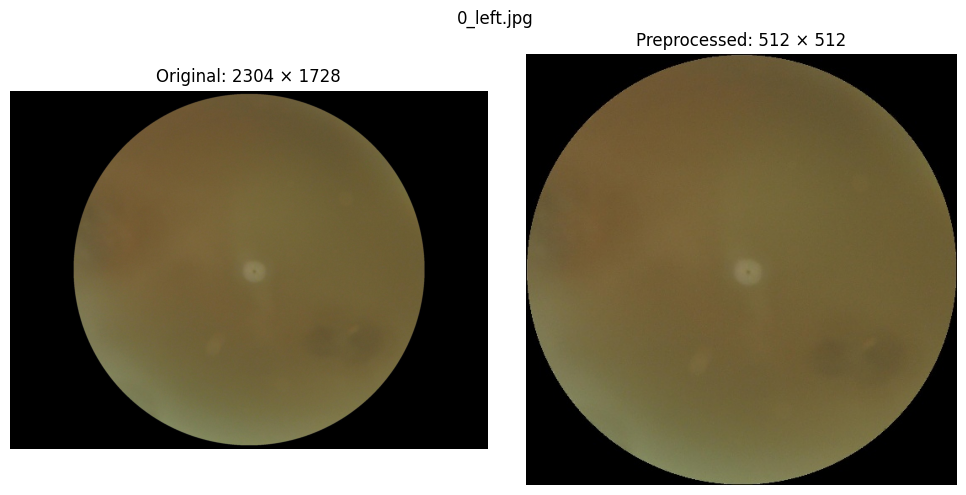

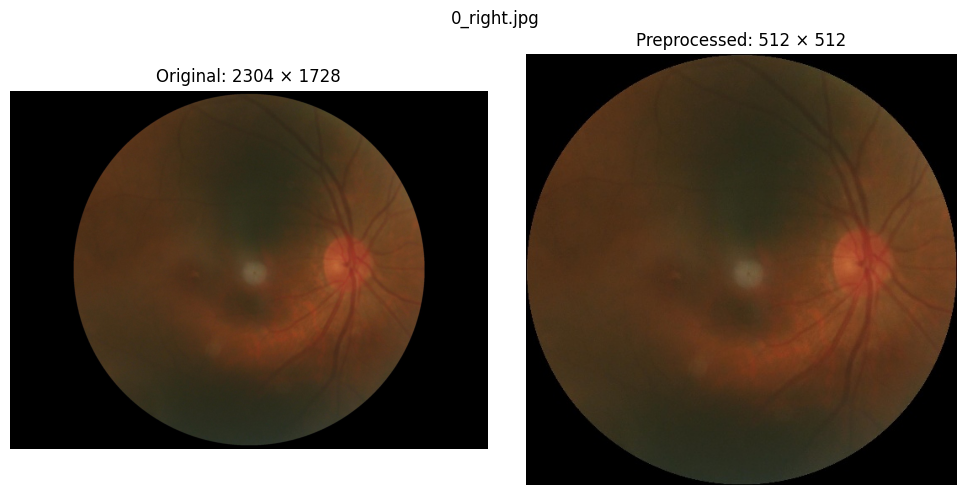

Skipping 1000_left.jpg: matching image missing from one folder.
Skipping 1000_right.jpg: matching image missing from one folder.


In [24]:
# Visually inspect representative images

original_dir = dataset_path / "ODIR-5K"
preprocessed_dir = dataset_path / "preprocessed_images"

# Choose filenames present in both collections
candidate_names = [
    "0_left.jpg",
    "0_right.jpg",
    "1000_left.jpg",
    "1000_right.jpg"
]

for filename in candidate_names:
    original_matches = list(original_dir.rglob(filename))
    preprocessed_matches = list(preprocessed_dir.rglob(filename))

    if not original_matches or not preprocessed_matches:
        print(f"Skipping {filename}: matching image missing from one folder.")
        continue

    with Image.open(original_matches[0]) as img:
        original_image = img.copy()

    with Image.open(preprocessed_matches[0]) as img:
        preprocessed_image = img.copy()

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].imshow(original_image)
    axes[0].set_title(
        f"Original: {original_image.width} × {original_image.height}"
    )
    axes[0].axis("off")

    axes[1].imshow(preprocessed_image)
    axes[1].set_title(
        f"Preprocessed: {preprocessed_image.width} × {preprocessed_image.height}"
    )
    axes[1].axis("off")

    fig.suptitle(filename)
    plt.tight_layout()
    plt.show()

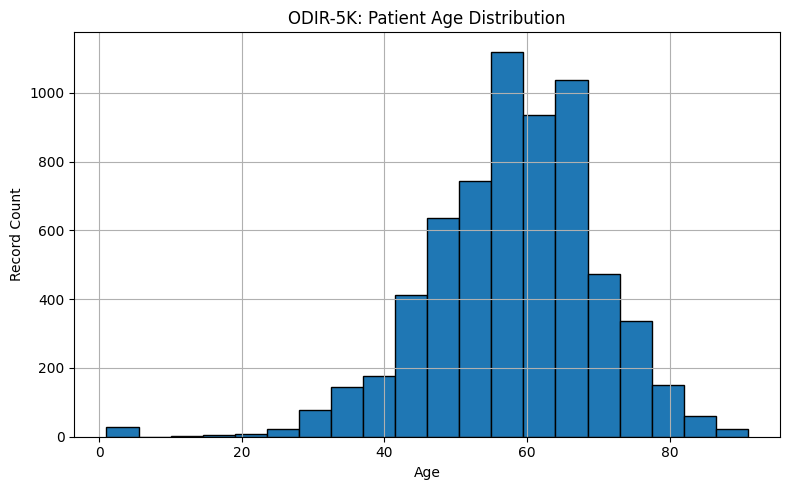

PATIENT SEX DISTRIBUTION


,record_count,percentage
Patient Sex,,
Male,3424,53.57
Female,2968,46.43


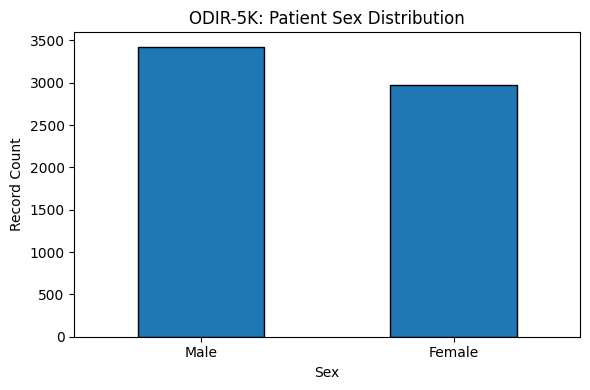

EYE-LEVEL LABEL DISTRIBUTION


,record_count,percentage
labels,,
N,2873,44.95
D,1608,25.16
O,708,11.08
C,293,4.58
G,284,4.44
A,266,4.16
M,232,3.63
H,128,2.00


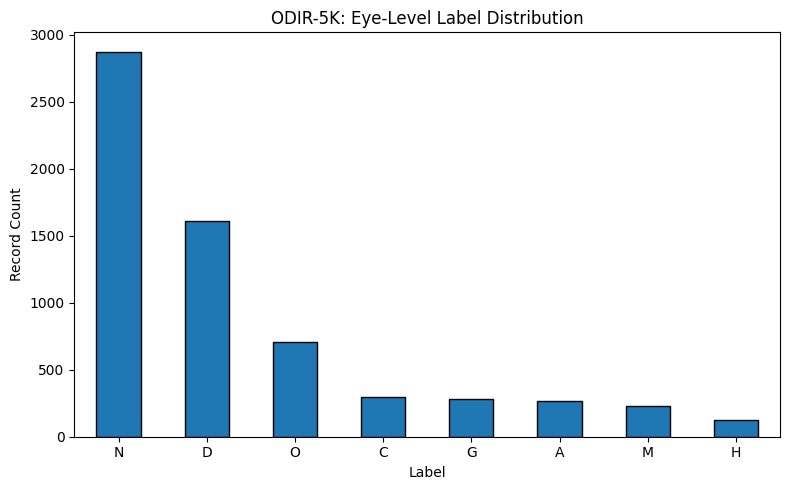

DISEASE INDICATOR DISTRIBUTIONS


,positive_records,negative_records,positive_percentage
D,2123,4269,33.21
N,2101,4291,32.87
O,1588,4804,24.84
C,402,5990,6.29
G,397,5995,6.21
A,319,6073,4.99
M,306,6086,4.79
H,203,6189,3.18


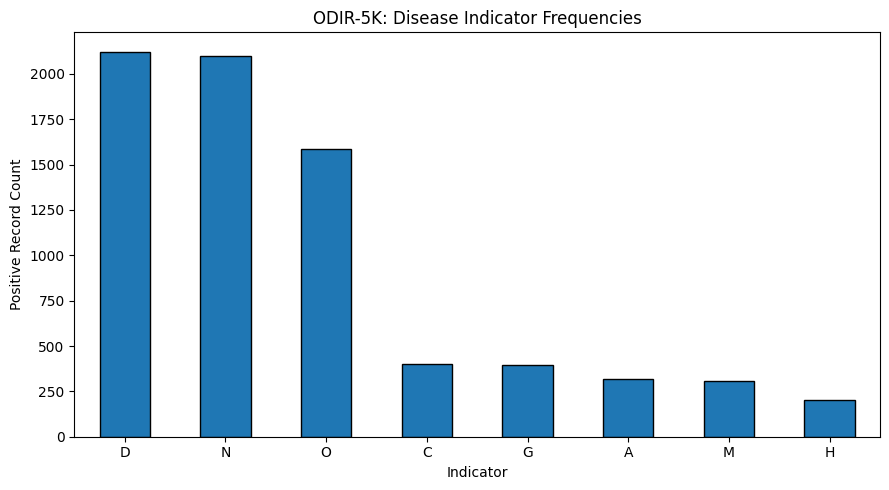

In [25]:
# Feature distributions

import pandas as pd
import matplotlib.pyplot as plt
import ast

# Convert age to numeric
df_csv["Patient Age"] = pd.to_numeric(
    df_csv["Patient Age"], errors="coerce"
)

# 1. Patient age distribution
plt.figure(figsize=(8, 5))
df_csv["Patient Age"].dropna().hist(bins=20, edgecolor="black")
plt.title("ODIR-5K: Patient Age Distribution")
plt.xlabel("Age")
plt.ylabel("Record Count")
plt.tight_layout()
plt.show()

# 2. Patient sex distribution
print("PATIENT SEX DISTRIBUTION")
display(
    df_csv["Patient Sex"]
    .value_counts(dropna=False)
    .to_frame("record_count")
    .assign(
        percentage=lambda x: (
            x["record_count"] / len(df_csv) * 100
        ).round(2)
    )
)

df_csv["Patient Sex"].value_counts().plot(
    kind="bar", figsize=(6, 4), edgecolor="black"
)
plt.title("ODIR-5K: Patient Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Record Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Eye-level label distribution
def parse_label(value):
    if pd.isna(value):
        return []
    if isinstance(value, list):
        return value
    try:
        parsed = ast.literal_eval(str(value))
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []

parsed_labels = df_csv["labels"].apply(parse_label)
label_counts = parsed_labels.explode().value_counts()

print("EYE-LEVEL LABEL DISTRIBUTION")
display(
    label_counts.to_frame("record_count")
    .assign(
        percentage=lambda x: (
            x["record_count"] / len(df_csv) * 100
        ).round(2)
    )
)

label_counts.plot(kind="bar", figsize=(8, 5), edgecolor="black")
plt.title("ODIR-5K: Eye-Level Label Distribution")
plt.xlabel("Label")
plt.ylabel("Record Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Disease-indicator distributions
indicator_columns = ["N", "D", "G", "C", "A", "H", "M", "O"]

indicator_counts = df_csv[indicator_columns].sum().sort_values(
    ascending=False
)

print("DISEASE INDICATOR DISTRIBUTIONS")
display(
    pd.DataFrame({
        "positive_records": indicator_counts,
        "negative_records": len(df_csv) - indicator_counts,
        "positive_percentage": (
            indicator_counts / len(df_csv) * 100
        ).round(2)
    })
)

indicator_counts.plot(kind="bar", figsize=(9, 5), edgecolor="black")
plt.title("ODIR-5K: Disease Indicator Frequencies")
plt.xlabel("Indicator")
plt.ylabel("Positive Record Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

CORRELATION MATRIX


,Patient Age,N,D,G,C,A,H,M,O
Patient Age,1.000,-0.067,-0.091,0.100,0.190,0.058,-0.026,-0.025,0.072
N,-0.067,1.000,-0.493,-0.180,-0.181,-0.160,-0.127,-0.157,-0.402
D,-0.091,-0.493,1.000,-0.104,-0.081,-0.113,0.041,-0.102,-0.023
G,0.100,-0.180,-0.104,1.000,-0.051,0.001,0.009,-0.018,-0.031
C,0.190,-0.181,-0.081,-0.051,1.000,-0.059,-0.032,-0.058,-0.065
A,0.058,-0.160,-0.113,0.001,-0.059,1.000,-0.009,-0.038,-0.089
H,-0.026,-0.127,0.041,0.009,-0.032,-0.009,1.000,-0.041,-0.061
M,-0.025,-0.157,-0.102,-0.018,-0.058,-0.038,-0.041,1.000,-0.031
O,0.072,-0.402,-0.023,-0.031,-0.065,-0.089,-0.061,-0.031,1.000


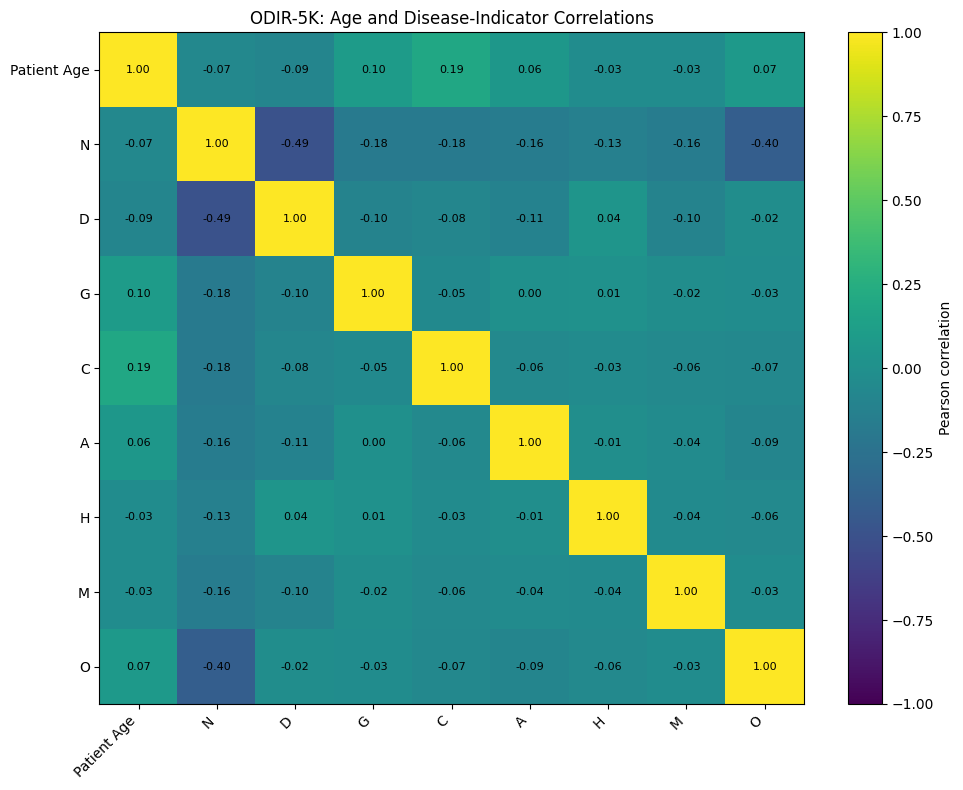

In [26]:
# Correlation analysis


# Numeric demographic feature
df_csv["Patient Age"] = pd.to_numeric(
    df_csv["Patient Age"], errors="coerce"
)

# Binary disease-indicator columns
indicator_columns = ["N", "D", "G", "C", "A", "H", "M", "O"]

# Use age and disease indicators; exclude ID and other identifiers
correlation_columns = ["Patient Age"] + indicator_columns

correlation_data = df_csv[correlation_columns].apply(
    pd.to_numeric, errors="coerce"
)

correlation_matrix = correlation_data.corr(method="pearson")

print("CORRELATION MATRIX")
display(correlation_matrix.round(3))

plt.figure(figsize=(10, 8))
image = plt.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1,
    aspect="auto"
)
plt.colorbar(image, label="Pearson correlation")
plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)
plt.title("ODIR-5K: Age and Disease-Indicator Correlations")

for i in range(len(correlation_matrix.index)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

DISEASE-INDICATOR CORRELATION MATRIX


,N,D,G,C,A,H,M,O
N,1.000,-0.493,-0.180,-0.181,-0.160,-0.127,-0.157,-0.402
D,-0.493,1.000,-0.104,-0.081,-0.113,0.041,-0.102,-0.023
G,-0.180,-0.104,1.000,-0.051,0.001,0.009,-0.018,-0.031
C,-0.181,-0.081,-0.051,1.000,-0.059,-0.032,-0.058,-0.065
A,-0.160,-0.113,0.001,-0.059,1.000,-0.009,-0.038,-0.089
H,-0.127,0.041,0.009,-0.032,-0.009,1.000,-0.041,-0.061
M,-0.157,-0.102,-0.018,-0.058,-0.038,-0.041,1.000,-0.031
O,-0.402,-0.023,-0.031,-0.065,-0.089,-0.061,-0.031,1.000


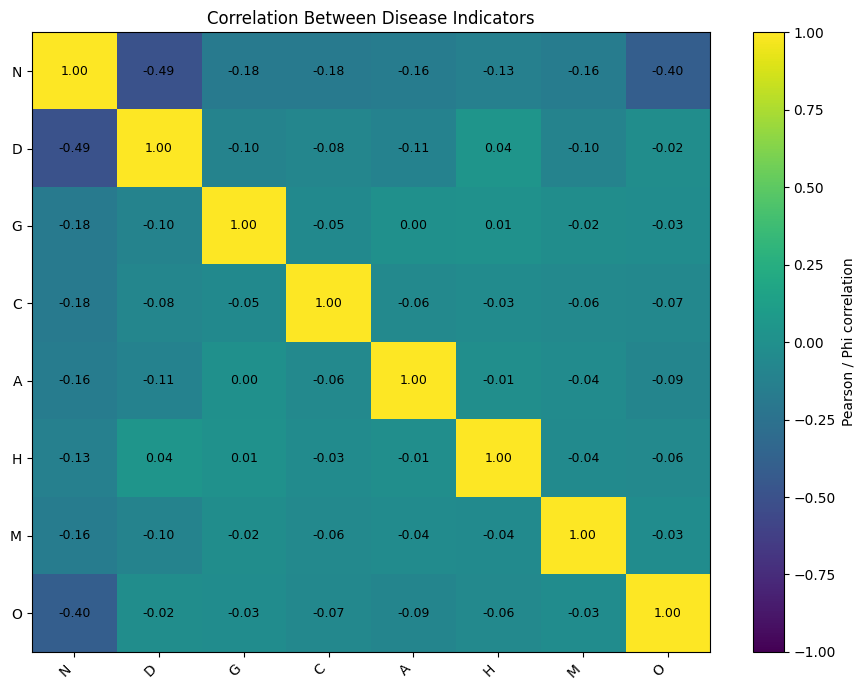

STRONGEST POSITIVE CORRELATIONS


,indicator_1,indicator_2,correlation,both_active_records,jaccard_similarity
0,D,H,0.041,89,0.040
1,G,H,0.009,15,0.026
2,G,A,0.001,20,0.029
3,A,H,-0.009,8,0.016
4,G,M,-0.018,13,0.019
5,D,O,-0.023,497,0.155
6,G,O,-0.031,78,0.041
7,M,O,-0.031,58,0.032
8,C,H,-0.032,4,0.007
9,A,M,-0.038,4,0.006


STRONGEST NEGATIVE CORRELATIONS


,indicator_1,indicator_2,correlation,both_active_records,jaccard_similarity
0,N,D,-0.493,0,0.000
1,N,O,-0.402,0,0.000
2,N,C,-0.181,0,0.000
3,N,G,-0.180,0,0.000
4,N,A,-0.160,0,0.000
5,N,M,-0.157,0,0.000
6,N,H,-0.127,0,0.000
7,D,A,-0.113,32,0.013
8,D,G,-0.104,56,0.023
9,D,M,-0.102,36,0.015


PAIRS WITH THE MOST CO-OCCURRENCES


,indicator_1,indicator_2,correlation,both_active_records,jaccard_similarity
0,D,O,-0.023,497,0.155
1,D,H,0.041,89,0.040
2,G,O,-0.031,78,0.041
3,D,C,-0.081,74,0.030
4,M,O,-0.031,58,0.032
5,C,O,-0.065,56,0.029
6,D,G,-0.104,56,0.023
7,D,M,-0.102,36,0.015
8,D,A,-0.113,32,0.013
9,A,O,-0.089,26,0.014


In [27]:
# Disease-indicator correlation analysis

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

indicator_columns = ["N", "D", "G", "C", "A", "H", "M", "O"]

# Keep only the disease-indicator columns
indicator_data = df_csv[indicator_columns].apply(
    pd.to_numeric, errors="coerce"
)

# Correlation between every pair of indicators
disease_corr = indicator_data.corr(method="pearson")

print("DISEASE-INDICATOR CORRELATION MATRIX")
display(disease_corr.round(3))

# Heatmap
plt.figure(figsize=(9, 7))
image = plt.imshow(
    disease_corr,
    vmin=-1,
    vmax=1,
    aspect="auto"
)
plt.colorbar(image, label="Pearson / Phi correlation")
plt.xticks(
    range(len(indicator_columns)),
    indicator_columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(indicator_columns)), indicator_columns)
plt.title("Correlation Between Disease Indicators")

for i in range(len(indicator_columns)):
    for j in range(len(indicator_columns)):
        plt.text(
            j, i, f"{disease_corr.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=9
        )

plt.tight_layout()
plt.show()

# Rank unique pairs, excluding self-correlations and duplicate pairs
pair_results = []

for i in range(len(indicator_columns)):
    for j in range(i + 1, len(indicator_columns)):
        a = indicator_columns[i]
        b = indicator_columns[j]

        valid = indicator_data[[a, b]].dropna()
        both_active = int(
            ((valid[a] == 1) & (valid[b] == 1)).sum()
        )
        either_active = int(
            ((valid[a] == 1) | (valid[b] == 1)).sum()
        )

        jaccard = (
            both_active / either_active
            if either_active > 0 else np.nan
        )

        pair_results.append({
            "indicator_1": a,
            "indicator_2": b,
            "correlation": valid[a].corr(valid[b]),
            "both_active_records": both_active,
            "jaccard_similarity": jaccard
        })

pair_df = pd.DataFrame(pair_results)
pair_df["correlation"] = pair_df["correlation"].round(3)
pair_df["jaccard_similarity"] = pair_df["jaccard_similarity"].round(3)

print("STRONGEST POSITIVE CORRELATIONS")
display(
    pair_df.sort_values("correlation", ascending=False).head(10)
    .reset_index(drop=True)
)

print("STRONGEST NEGATIVE CORRELATIONS")
display(
    pair_df.sort_values("correlation", ascending=True).head(10)
    .reset_index(drop=True)
)

print("PAIRS WITH THE MOST CO-OCCURRENCES")
display(
    pair_df.sort_values("both_active_records", ascending=False).head(10)
    .reset_index(drop=True)
)

In [28]:
# Disease prevalence by age group

# Disease indicator columns
disease_cols = ["N", "D", "G", "C", "A", "H", "M", "O"]

# Create age groups
age_bins = [0, 17, 29, 39, 49, 59, 69, 79, np.inf]
age_labels = [
    "0–17", "18–29", "30–39", "40–49",
    "50–59", "60–69", "70–79", "80+"
]

df_csv["age_group"] = pd.cut(
    df_csv["Patient Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# Calculate the percentage of records with each indicator
age_disease_prevalence = (
    df_csv.groupby("age_group", observed=False)[disease_cols]
    .mean()
    .mul(100)
    .round(2)
)

print("DISEASE INDICATOR PREVALENCE BY AGE GROUP (%)")
display(age_disease_prevalence)

print("\nRECORD COUNT BY AGE GROUP")
display(
    df_csv["age_group"]
    .value_counts(sort=False)
    .to_frame("record_count")
)


DISEASE INDICATOR PREVALENCE BY AGE GROUP (%)


,N,D,G,C,A,H,M,O
age_group,,,,,,,,
0–17,11.76,5.88,0.00,0.00,5.88,0.00,73.53,5.88
18–29,42.86,26.79,3.57,3.57,0.00,0.00,3.57,28.57
30–39,38.38,37.32,6.34,3.52,2.82,2.82,3.87,18.31
40–49,37.09,38.72,3.66,1.83,3.15,3.66,2.13,20.73
50–59,35.00,38.08,4.12,3.62,4.96,3.67,3.97,22.51
60–69,30.89,32.36,6.66,5.90,5.81,3.92,4.35,28.58
70–79,27.54,20.59,12.83,15.37,5.35,0.27,9.63,30.08
80+,21.71,7.89,13.82,38.82,9.87,0.00,1.97,19.74



RECORD COUNT BY AGE GROUP


,record_count
age_group,
0–17,34
18–29,56
30–39,284
40–49,984
50–59,2017
60–69,2117
70–79,748
80+,152


In [29]:
# Measure age–disease correlations


from scipy.stats import pearsonr, spearmanr

results = []

for col in disease_cols:
    valid = df_csv[["Patient Age", col]].dropna()

    pearson_r, pearson_p = pearsonr(
        valid["Patient Age"], valid[col]
    )
    spearman_r, spearman_p = spearmanr(
        valid["Patient Age"], valid[col]
    )

    results.append({
        "indicator": col,
        "pearson_correlation": round(pearson_r, 3),
        "pearson_p_value": pearson_p,
        "spearman_correlation": round(spearman_r, 3),
        "spearman_p_value": spearman_p,
        "record_count": len(valid)
    })

age_correlation = (
    pd.DataFrame(results)
    .sort_values("spearman_correlation", ascending=False)
    .reset_index(drop=True)
)

print("AGE–DISEASE INDICATOR CORRELATIONS")
display(age_correlation.round(4))


AGE–DISEASE INDICATOR CORRELATIONS


,indicator,pearson_correlation,pearson_p_value,spearman_correlation,spearman_p_value,record_count
0,C,0.190,0.0000,0.186,0.0000,6392
1,G,0.100,0.0000,0.107,0.0000,6392
2,O,0.072,0.0000,0.080,0.0000,6392
3,A,0.058,0.0000,0.062,0.0000,6392
4,M,-0.025,0.0433,0.037,0.0031,6392
5,H,-0.026,0.0342,-0.035,0.0056,6392
6,N,-0.067,0.0000,-0.079,0.0000,6392
7,D,-0.091,0.0000,-0.111,0.0000,6392


TOP 15 LEFT-EYE DIAGNOSTIC KEYWORD STRINGS


,record_count
Left-Diagnostic Keywords,
normal fundus,2796
moderate non proliferative retinopathy,717
mild nonproliferative retinopathy,428
cataract,268
pathological myopia,208
glaucoma,207
dry age-related macular degeneration,184
severe nonproliferative retinopathy,139
drusen,130



TOP 15 RIGHT-EYE DIAGNOSTIC KEYWORD STRINGS


,record_count
Right-Diagnostic Keywords,
normal fundus,2705
moderate non proliferative retinopathy,745
mild nonproliferative retinopathy,472
cataract,250
pathological myopia,216
dry age-related macular degeneration,204
glaucoma,190
severe nonproliferative retinopathy,147
macular epiretinal membrane,141



TOP 20 KEYWORD STRINGS ACROSS BOTH EYES


,record_count,percentage
normal fundus,5501,43.03
moderate non proliferative retinopathy,1462,11.44
mild nonproliferative retinopathy,900,7.04
cataract,518,4.05
pathological myopia,424,3.32
glaucoma,397,3.11
dry age-related macular degeneration,388,3.04
severe nonproliferative retinopathy,286,2.24
drusen,270,2.11
macular epiretinal membrane,238,1.86


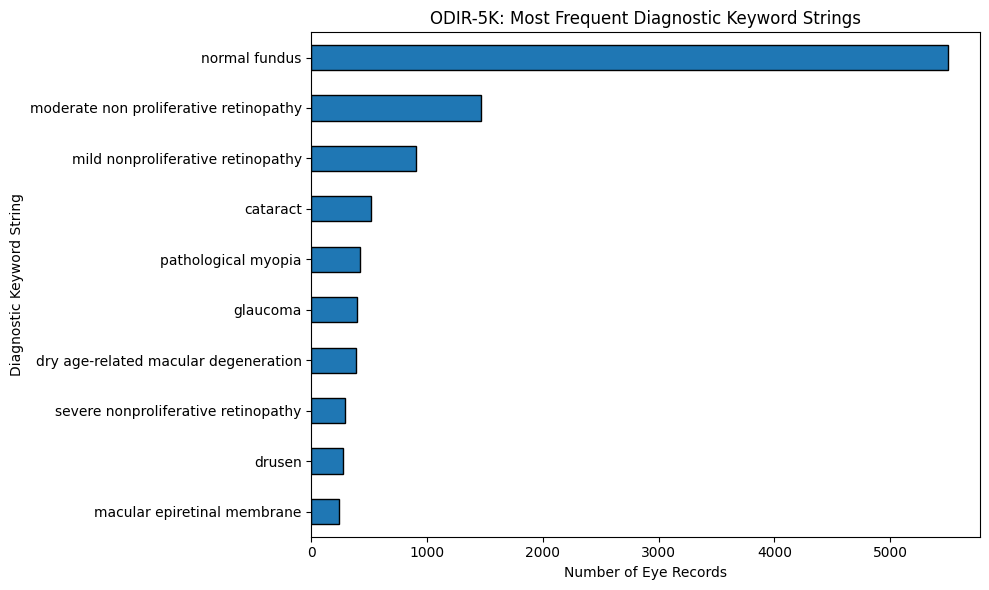

In [30]:
# Analyze diagnostic keyword frequencies


import pandas as pd
import matplotlib.pyplot as plt

# Count complete diagnostic keyword strings for each eye
left_keywords = (
    df_csv["Left-Diagnostic Keywords"]
    .fillna("Missing")
    .value_counts()
)

right_keywords = (
    df_csv["Right-Diagnostic Keywords"]
    .fillna("Missing")
    .value_counts()
)

print("TOP 15 LEFT-EYE DIAGNOSTIC KEYWORD STRINGS")
display(left_keywords.head(15).to_frame("record_count"))

print("\nTOP 15 RIGHT-EYE DIAGNOSTIC KEYWORD STRINGS")
display(right_keywords.head(15).to_frame("record_count"))

# Compare the most common strings across both eyes
combined_keywords = pd.concat([
    df_csv["Left-Diagnostic Keywords"].fillna("Missing"),
    df_csv["Right-Diagnostic Keywords"].fillna("Missing")
])

combined_counts = combined_keywords.value_counts()

print("\nTOP 20 KEYWORD STRINGS ACROSS BOTH EYES")
display(
    combined_counts.head(20)
    .to_frame("record_count")
    .assign(
        percentage=lambda x: (
            x["record_count"] / len(combined_keywords) * 100
        ).round(2)
    )
)

# Visualize the 10 most frequent strings
top_10 = combined_counts.head(10).sort_values()

plt.figure(figsize=(10, 6))
top_10.plot(kind="barh", edgecolor="black")
plt.title("ODIR-5K: Most Frequent Diagnostic Keyword Strings")
plt.xlabel("Number of Eye Records")
plt.ylabel("Diagnostic Keyword String")
plt.tight_layout()
plt.show()



NUMBER OF DESCRIPTIONS PER EYE-LEVEL KEYWORD ENTRY


,record_count,percentage
1,12782,99.98
2,2,0.02



ENTRIES CONTAINING MULTIPLE DESCRIPTIONS
Total multi-description entries: 2
Percentage: 0.02 %

TOP 15 MULTI-DESCRIPTION KEYWORD STRINGS


,record_count
"hypertensive retinopathy,diabetic retinopathy",1
"low image quality,maculopathy",1


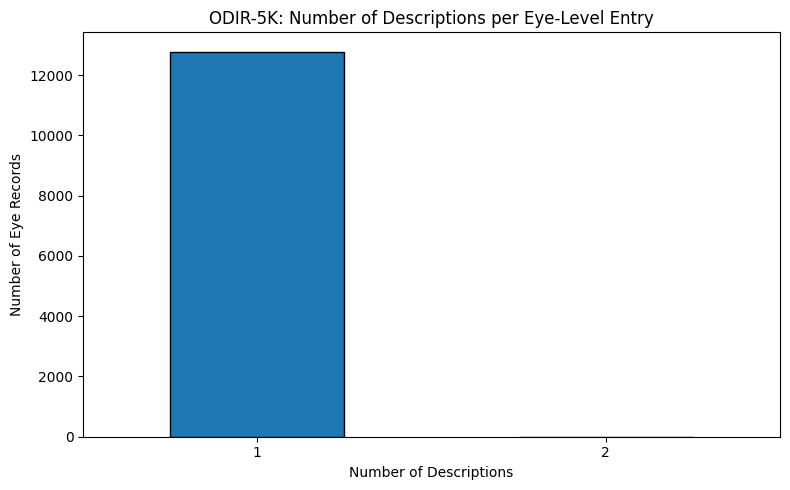

In [31]:
# Examine multi-diagnosis keyword strings

import pandas as pd
import matplotlib.pyplot as plt

keyword_columns = [
    "Left-Diagnostic Keywords",
    "Right-Diagnostic Keywords"
]

all_keywords = pd.concat(
    [
        df_csv[col].fillna("").astype(str)
        for col in keyword_columns
    ],
    ignore_index=True
)

# Count comma-separated descriptions in each eye-level entry
keyword_counts = all_keywords.apply(
    lambda value: (
        len([item for item in value.split(",") if item.strip()])
        if value.strip()
        else 0
    )
)

summary = keyword_counts.value_counts().sort_index()

print("NUMBER OF DESCRIPTIONS PER EYE-LEVEL KEYWORD ENTRY")
display(
    summary.to_frame("record_count")
    .assign(
        percentage=lambda x: (
            x["record_count"] / len(keyword_counts) * 100
        ).round(2)
    )
)

print("\nENTRIES CONTAINING MULTIPLE DESCRIPTIONS")
multi_keyword = all_keywords[keyword_counts > 1]

print("Total multi-description entries:", len(multi_keyword))
print(
    "Percentage:",
    round(len(multi_keyword) / len(all_keywords) * 100, 2),
    "%"
)

print("\nTOP 15 MULTI-DESCRIPTION KEYWORD STRINGS")
display(
    multi_keyword.value_counts().head(15).to_frame("record_count")
)

summary.plot(kind="bar", figsize=(8, 5), edgecolor="black")
plt.title("ODIR-5K: Number of Descriptions per Eye-Level Entry")
plt.xlabel("Number of Descriptions")
plt.ylabel("Number of Eye Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

LEFT VS RIGHT EYE KEYWORD COMPARISON
Total records: 6392
Same keyword string: 3692
Different keyword strings: 2700
Same keyword percentage: 57.76 %
Different keyword percentage: 42.24 %

TOP 15 MATCHING LEFT-RIGHT KEYWORD PAIRS


,Left,Right,record_count
0,normal fundus,normal fundus,2002
1,moderate non proliferative retinopathy,moderate non proliferative retinopathy,452
2,cataract,cataract,158
3,dry age-related macular degeneration,dry age-related macular degeneration,158
4,glaucoma,glaucoma,154
5,pathological myopia,pathological myopia,150
6,mild nonproliferative retinopathy,mild nonproliferative retinopathy,150
7,severe nonproliferative retinopathy,severe nonproliferative retinopathy,110
8,drusen,drusen,76
9,hypertensive retinopathy,hypertensive retinopathy,72



TOP 15 DIFFERING LEFT-RIGHT KEYWORD PAIRS


,Left,Right,record_count
0,normal fundus,mild nonproliferative retinopathy,174
1,mild nonproliferative retinopathy,normal fundus,120
2,normal fundus,macular epiretinal membrane,96
3,mild nonproliferative retinopathy,moderate non proliferative retinopathy,88
4,macular epiretinal membrane,normal fundus,66
5,normal fundus,moderate non proliferative retinopathy,66
6,moderate non proliferative retinopathy,mild nonproliferative retinopathy,66
7,normal fundus,epiretinal membrane,60
8,moderate non proliferative retinopathy,normal fundus,50
9,cataract,normal fundus,48


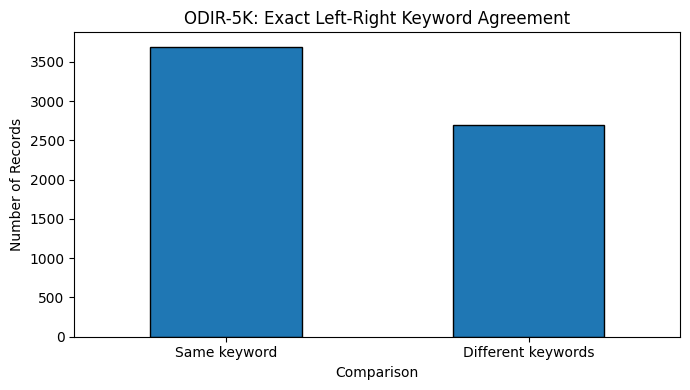

In [32]:
# Compare left-eye and right-eye diagnostic keywords


left = df_csv["Left-Diagnostic Keywords"].fillna("Missing").astype(str).str.strip()
right = df_csv["Right-Diagnostic Keywords"].fillna("Missing").astype(str).str.strip()

same_keyword = left == right

print("LEFT VS RIGHT EYE KEYWORD COMPARISON")
print("Total records:", len(df_csv))
print("Same keyword string:", int(same_keyword.sum()))
print("Different keyword strings:", int((~same_keyword).sum()))
print("Same keyword percentage:", round(same_keyword.mean() * 100, 2), "%")
print("Different keyword percentage:", round((~same_keyword).mean() * 100, 2), "%")

print("\nTOP 15 MATCHING LEFT-RIGHT KEYWORD PAIRS")
matching_pairs = (
    pd.DataFrame({"Left": left[same_keyword], "Right": right[same_keyword]})
    .value_counts()
    .head(15)
    .rename("record_count")
    .reset_index()
)
display(matching_pairs)

print("\nTOP 15 DIFFERING LEFT-RIGHT KEYWORD PAIRS")
different_pairs = (
    pd.DataFrame({"Left": left[~same_keyword], "Right": right[~same_keyword]})
    .value_counts()
    .head(15)
    .rename("record_count")
    .reset_index()
)
display(different_pairs)

comparison_counts = pd.Series({
    "Same keyword": int(same_keyword.sum()),
    "Different keywords": int((~same_keyword).sum())
})

comparison_counts.plot(kind="bar", figsize=(7, 4), edgecolor="black")
plt.title("ODIR-5K: Exact Left-Right Keyword Agreement")
plt.xlabel("Comparison")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

LEFT-RIGHT NORMAL FUNDUS ANNOTATION PATTERNS


,record_count,percentage
eye_annotation_pattern,,
Both normal fundus,2002,31.32
"Left normal, right non-normal",794,12.42
"Left non-normal, right normal",703,11.00
Both non-normal,2893,45.26


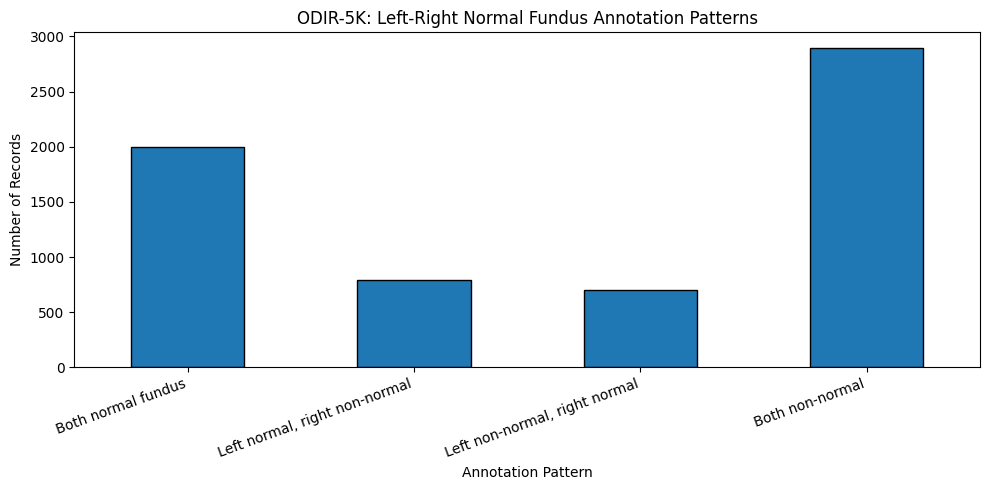

In [33]:
# Compare normal and non-normal eye annotations



left = (
    df_csv["Left-Diagnostic Keywords"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

right = (
    df_csv["Right-Diagnostic Keywords"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

left_normal = left.eq("normal fundus")
right_normal = right.eq("normal fundus")

conditions = [
    left_normal & right_normal,
    left_normal & ~right_normal,
    ~left_normal & right_normal,
    ~left_normal & ~right_normal
]

categories = [
    "Both normal fundus",
    "Left normal, right non-normal",
    "Left non-normal, right normal",
    "Both non-normal"
]

df_csv["eye_annotation_pattern"] = pd.Series(
    pd.NA, index=df_csv.index, dtype="object"
)

for condition, category in zip(conditions, categories):
    df_csv.loc[condition, "eye_annotation_pattern"] = category

pattern_counts = (
    df_csv["eye_annotation_pattern"]
    .value_counts()
    .reindex(categories, fill_value=0)
)

pattern_summary = pd.DataFrame({
    "record_count": pattern_counts,
    "percentage": (pattern_counts / len(df_csv) * 100).round(2)
})

print("LEFT-RIGHT NORMAL FUNDUS ANNOTATION PATTERNS")
display(pattern_summary)

pattern_counts.plot(kind="bar", figsize=(10, 5), edgecolor="black")
plt.title("ODIR-5K: Left-Right Normal Fundus Annotation Patterns")
plt.xlabel("Annotation Pattern")
plt.ylabel("Number of Records")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

PREPROCESSED IMAGE INVENTORY
Total image files: 6392
Readable images: 6392
Unreadable images: 0

IMAGE DIMENSION DISTRIBUTION


,width,height,image_count
0,512,512,6392



FILE SIZE SUMMARY (KB)


,value
count,6392.000000
mean,60.671694
std,12.976204
min,27.150000
25%,51.980000
50%,59.300000
75%,67.660000
max,135.970000



IMAGE DIMENSION AND SIZE SUMMARY


,width,height,size_kb
count,6392.0,6392.0,6392.00
mean,512.0,512.0,60.67
std,0.0,0.0,12.98
min,512.0,512.0,27.15
25%,512.0,512.0,51.98
50%,512.0,512.0,59.30
75%,512.0,512.0,67.66
max,512.0,512.0,135.97


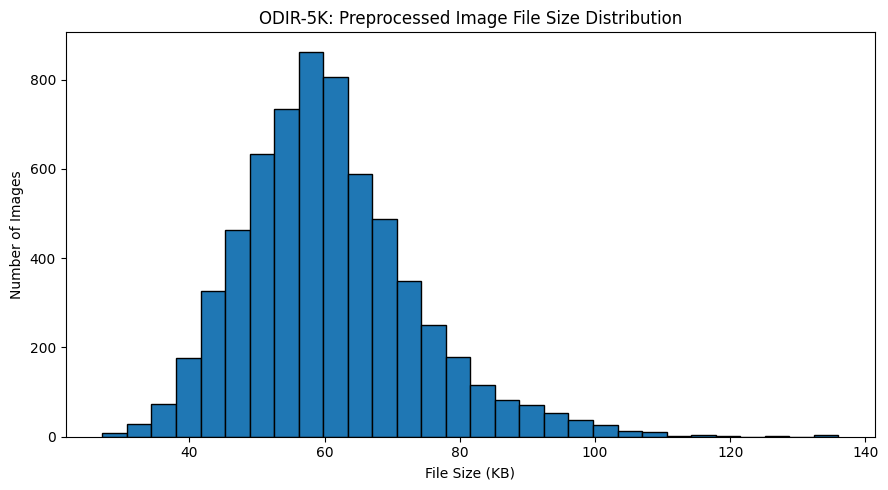

In [34]:
from pathlib import Path
import cv2
import pandas as pd
import matplotlib.pyplot as plt

image_dir = dataset_path / "preprocessed_images"
image_files = sorted(image_dir.glob("*"))

image_records = []

for image_path in image_files:
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue

    image = cv2.imread(str(image_path))

    if image is None:
        image_records.append({
            "filename": image_path.name,
            "width": None,
            "height": None,
            "size_kb": round(image_path.stat().st_size / 1024, 2),
            "readable": False
        })
        continue

    height, width = image.shape[:2]

    image_records.append({
        "filename": image_path.name,
        "width": width,
        "height": height,
        "size_kb": round(image_path.stat().st_size / 1024, 2),
        "readable": True
    })

image_stats = pd.DataFrame(image_records)

print("PREPROCESSED IMAGE INVENTORY")
print("Total image files:", len(image_stats))
print("Readable images:", int(image_stats["readable"].sum()))
print("Unreadable images:", int((~image_stats["readable"]).sum()))

print("\nIMAGE DIMENSION DISTRIBUTION")
display(
    image_stats[image_stats["readable"]]
    .groupby(["width", "height"])
    .size()
    .rename("image_count")
    .reset_index()
    .sort_values("image_count", ascending=False)
)

print("\nFILE SIZE SUMMARY (KB)")
display(image_stats["size_kb"].describe().to_frame("value"))

print("\nIMAGE DIMENSION AND SIZE SUMMARY")
display(
    image_stats[image_stats["readable"]][
        ["width", "height", "size_kb"]
    ].describe().round(2)
)

plt.figure(figsize=(9, 5))
image_stats.loc[image_stats["readable"], "size_kb"].plot(
    kind="hist", bins=30, edgecolor="black"
)
plt.title("ODIR-5K: Preprocessed Image File Size Distribution")
plt.xlabel("File Size (KB)")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

In [35]:

import pandas as pd
import json
from pathlib import Path

# 1. Missing values
print("1. MISSING VALUES")
missing_values = df_csv.isnull().sum()

if missing_values.sum() == 0:
    print("No missing values found.")
else:
    display(
        missing_values[missing_values > 0]
        .rename("missing_count")
        .to_frame()
    )

# 2. Duplicate record check
# Convert list/dict values to stable strings for comparison.
def make_hashable(value):
    if isinstance(value, (list, dict)):
        return json.dumps(value, sort_keys=True, default=str)
    if isinstance(value, set):
        return json.dumps(sorted(value, key=str), default=str)
    return value

safe_df = df_csv.map(make_hashable)

print("\n2. DUPLICATE RECORD CHECK")
print("Exact duplicate rows:", int(safe_df.duplicated().sum()))
print("Unique patient IDs:", df_csv["ID"].nunique())
print(
    "Rows with repeated patient IDs:",
    int(df_csv["ID"].duplicated(keep=False).sum())
)

# 3. Label-target consistency
label_target_match = (
    df_csv["labels"].astype(str).str.strip()
    == df_csv["target"].astype(str).str.strip()
)

print("\n3. LABEL-TARGET CONSISTENCY")
print("Matching labels and targets:", int(label_target_match.sum()))
print("Mismatches:", int((~label_target_match).sum()))

# 4. Image path integrity
image_root = dataset_path / "preprocessed_images"

if "filepath" in df_csv.columns:
    image_names = df_csv["filepath"].apply(
        lambda value: Path(str(value)).name
    )
else:
    image_names = df_csv["filename"].apply(
        lambda value: Path(str(value)).name
    )

image_exists = image_names.apply(
    lambda name: (image_root / name).is_file()
)

print("\n4. IMAGE PATH INTEGRITY")
print("Rows with existing preprocessed images:", int(image_exists.sum()))
print("Rows with missing image files:", int((~image_exists).sum()))

# 5. Final summary
print("\n5. FINAL VALIDATION SUMMARY")
print("Dataset shape:", df_csv.shape)
print("All labels match targets:", bool(label_target_match.all()))
print("All image paths exist:", bool(image_exists.all()))


1. MISSING VALUES
No missing values found.

2. DUPLICATE RECORD CHECK
Exact duplicate rows: 0
Unique patient IDs: 3358
Rows with repeated patient IDs: 6068

3. LABEL-TARGET CONSISTENCY
Matching labels and targets: 0
Mismatches: 6392

4. IMAGE PATH INTEGRITY
Rows with existing preprocessed images: 6392
Rows with missing image files: 0

5. FINAL VALIDATION SUMMARY
Dataset shape: (6392, 26)
All labels match targets: False
All image paths exist: True


In [36]:
print("DATAFRAME SHAPE:", df_csv.shape)

print("\nLABEL COLUMN TYPE:")
print(df_csv["labels"].apply(type).value_counts())
print("\nTARGET COLUMN TYPE:")
print(df_csv["target"].apply(type).value_counts())

print("\nSAMPLE LABEL VALUES:")
display(df_csv["labels"].head(10).to_frame())

print("\nSAMPLE TARGET VALUES:")
display(df_csv["target"].head(10).to_frame())

print("\nSAMPLE LABEL-TARGET PAIRS:")
display(df_csv[["labels", "target"]].head(15))

print("\nDATAFRAME COLUMNS:")
print(df_csv.columns.tolist())

DATAFRAME SHAPE: (6392, 26)

LABEL COLUMN TYPE:
labels
<class 'str'>    6392
Name: count, dtype: int64

TARGET COLUMN TYPE:
target
<class 'str'>    6392
Name: count, dtype: int64

SAMPLE LABEL VALUES:


,labels
0,['N']
1,['N']
2,['D']
3,['D']
4,['D']
5,['D']
6,['D']
7,['N']
8,['O']
9,['N']



SAMPLE TARGET VALUES:


,target
0,"[1, 0, 0, 0, 0, 0, 0, 0]"
1,"[1, 0, 0, 0, 0, 0, 0, 0]"
2,"[0, 1, 0, 0, 0, 0, 0, 0]"
3,"[0, 1, 0, 0, 0, 0, 0, 0]"
4,"[0, 1, 0, 0, 0, 0, 0, 0]"
5,"[0, 1, 0, 0, 0, 0, 0, 0]"
6,"[0, 1, 0, 0, 0, 0, 0, 0]"
7,"[1, 0, 0, 0, 0, 0, 0, 0]"
8,"[0, 0, 0, 0, 0, 0, 0, 1]"
9,"[1, 0, 0, 0, 0, 0, 0, 0]"



SAMPLE LABEL-TARGET PAIRS:


,labels,target
0,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"
1,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"
2,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
3,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
4,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
5,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
6,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
7,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"
8,['O'],"[0, 0, 0, 0, 0, 0, 0, 1]"
9,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"



DATAFRAME COLUMNS:
['ID', 'Patient Age', 'Patient Sex', 'Left-Fundus', 'Right-Fundus', 'Left-Diagnostic Keywords', 'Right-Diagnostic Keywords', 'N', 'D', 'G', 'C', 'A', 'H', 'M', 'O', 'filepath', 'labels', 'target', 'filename', 'selected_eye', 'section', 'parsed_labels', 'decoded_target', 'labels_target_match', 'age_group', 'eye_annotation_pattern']


In [37]:
import ast
import pandas as pd

# Convert string representations into actual Python lists
def parse_list(value):
    if isinstance(value, str):
        return ast.literal_eval(value)
    return value

labels_parsed = df_csv["labels"].apply(parse_list)
targets_parsed = df_csv["target"].apply(parse_list)

# ODIR-5K one-hot target order
class_order = ["N", "D", "G", "C", "A", "H", "M", "O"]

def decode_one_hot(vector):
    if len(vector) != len(class_order):
        return None

    active = [
        class_order[i]
        for i, value in enumerate(vector)
        if value == 1
    ]

    # A valid single-class one-hot vector has exactly one active position
    if len(active) != 1 or any(value not in (0, 1) for value in vector):
        return None

    return active

decoded_targets = targets_parsed.apply(decode_one_hot)

# Compare normalized labels with decoded target vectors
matches = pd.Series(
    [
        sorted(label) == sorted(decoded)
        if isinstance(label, list) and isinstance(decoded, list)
        else False
        for label, decoded in zip(labels_parsed, decoded_targets)
    ],
    index=df_csv.index
)

print("CORRECTED LABEL-TARGET VALIDATION")
print("Total records:", len(df_csv))
print("Matching records:", int(matches.sum()))
print("Mismatching records:", int((~matches).sum()))
print("Match percentage:", round(matches.mean() * 100, 2), "%")

print("\nSAMPLE MISMATCHES, IF ANY")
display(
    df_csv.loc[~matches, ["labels", "target"]].head(10)
)

print("\nFINAL STATUS")
print("All labels match targets:", bool(matches.all()))

CORRECTED LABEL-TARGET VALIDATION
Total records: 6392
Matching records: 6392
Mismatching records: 0
Match percentage: 100.0 %

SAMPLE MISMATCHES, IF ANY


,labels,target



FINAL STATUS
All labels match targets: True


In [38]:
# 1. Display the original dataset columns
original_columns = [
    'ID',
    'Patient Age',
    'Patient Sex',
    'Left-Fundus',
    'Right-Fundus',
    'Left-Diagnostic Keywords',
    'Right-Diagnostic Keywords',
    'N', 'D', 'G', 'C', 'A', 'H', 'M', 'O',
    'filepath',
    'labels',
    'target',
    'filename'
]

# 2. List the seven derived columns
derived_columns = [
    'selected_eye',
    'section',
    'parsed_labels',
    'decoded_target',
    'labels_target_match',
    'age_group',
    'eye_annotation_pattern'
]

# 3. Print the comparison
print("=" * 60)
print("ORIGINAL DATASET")
print("=" * 60)

print("Original column count:", len(original_columns))

for i, col in enumerate(original_columns, start=1):
    print(f"{i:2}. {col}")

print("\n" + "=" * 60)
print("COLUMNS CREATED DURING EDA")
print("=" * 60)

print("Derived column count:", len(derived_columns))

for i, col in enumerate(derived_columns, start=20):
    print(f"{i:2}. {col}")

print("\n" + "=" * 60)
print("FINAL DATAFRAME")
print("=" * 60)

print("Actual shape:", df_csv.shape)
print("Actual column count:", len(df_csv.columns))
print("Total expected columns:", len(original_columns) + len(derived_columns))

print("\nAll actual DataFrame columns:")
for i, col in enumerate(df_csv.columns, start=1):
    category = (
        "Original"
        if col in original_columns
        else "EDA-derived"
    )
    print(f"{i:2}. {col:<30} [{category}]")

ORIGINAL DATASET
Original column count: 19
 1. ID
 2. Patient Age
 3. Patient Sex
 4. Left-Fundus
 5. Right-Fundus
 6. Left-Diagnostic Keywords
 7. Right-Diagnostic Keywords
 8. N
 9. D
10. G
11. C
12. A
13. H
14. M
15. O
16. filepath
17. labels
18. target
19. filename

COLUMNS CREATED DURING EDA
Derived column count: 7
20. selected_eye
21. section
22. parsed_labels
23. decoded_target
24. labels_target_match
25. age_group
26. eye_annotation_pattern

FINAL DATAFRAME
Actual shape: (6392, 26)
Actual column count: 26
Total expected columns: 26

All actual DataFrame columns:
 1. ID                             [Original]
 2. Patient Age                    [Original]
 3. Patient Sex                    [Original]
 4. Left-Fundus                    [Original]
 5. Right-Fundus                   [Original]
 6. Left-Diagnostic Keywords       [Original]
 7. Right-Diagnostic Keywords      [Original]
 8. N                              [Original]
 9. D                              [Original]
10. G    

In [39]:
import pandas as pd
from IPython.display import display

# Display all 26 columns in the DataFrame
with pd.option_context(
    'display.max_columns', None,
    'display.max_rows', 10,
    'display.max_colwidth', 30,
    'display.width', None
):
    display(df_csv.head(10))

,ID,Patient Age,Patient Sex,Left-Fundus,Right-Fundus,Left-Diagnostic Keywords,Right-Diagnostic Keywords,N,D,G,C,A,H,M,O,filepath,labels,target,filename,selected_eye,section,parsed_labels,decoded_target,labels_target_match,age_group,eye_annotation_pattern
0,0,69,Female,0_left.jpg,0_right.jpg,cataract,normal fundus,0,0,0,1,0,0,0,0,../input/ocular-disease-re...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",0_right.jpg,Right,First,[N],[N],True,60–69,"Left non-normal, right normal"
1,1,57,Male,1_left.jpg,1_right.jpg,normal fundus,normal fundus,1,0,0,0,0,0,0,0,../input/ocular-disease-re...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",1_right.jpg,Right,First,[N],[N],True,50–59,Both normal fundus
2,2,42,Male,2_left.jpg,2_right.jpg,laser spot，moderate non pr...,moderate non proliferative...,0,1,0,0,0,0,0,1,../input/ocular-disease-re...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",2_right.jpg,Right,First,[D],[D],True,40–49,Both non-normal
3,4,53,Male,4_left.jpg,4_right.jpg,macular epiretinal membrane,mild nonproliferative reti...,0,1,0,0,0,0,0,1,../input/ocular-disease-re...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",4_right.jpg,Right,First,[D],[D],True,50–59,Both non-normal
4,5,50,Female,5_left.jpg,5_right.jpg,moderate non proliferative...,moderate non proliferative...,0,1,0,0,0,0,0,0,../input/ocular-disease-re...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",5_right.jpg,Right,First,[D],[D],True,50–59,Both non-normal
5,6,60,Male,6_left.jpg,6_right.jpg,macular epiretinal membrane,moderate non proliferative...,0,1,0,0,0,0,0,1,../input/ocular-disease-re...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",6_right.jpg,Right,First,[D],[D],True,60–69,Both non-normal
6,7,60,Female,7_left.jpg,7_right.jpg,drusen,mild nonproliferative reti...,0,1,0,0,0,0,0,1,../input/ocular-disease-re...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",7_right.jpg,Right,First,[D],[D],True,60–69,Both non-normal
7,8,59,Male,8_left.jpg,8_right.jpg,normal fundus,normal fundus,1,0,0,0,0,0,0,0,../input/ocular-disease-re...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",8_right.jpg,Right,First,[N],[N],True,50–59,Both normal fundus
8,9,54,Male,9_left.jpg,9_right.jpg,normal fundus,vitreous degeneration,0,0,0,0,0,0,0,1,../input/ocular-disease-re...,['O'],"[0, 0, 0, 0, 0, 0, 0, 1]",9_right.jpg,Right,First,[O],[O],True,50–59,"Left normal, right non-normal"
9,10,70,Male,10_left.jpg,10_right.jpg,epiretinal membrane,normal fundus,0,0,0,0,0,0,0,1,../input/ocular-disease-re...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",10_right.jpg,Right,First,[N],[N],True,70–79,"Left non-normal, right normal"


In [40]:
import pandas as pd
from IPython.display import display

# 1. Keep only the original 19 columns in the original dataset view
original_columns = [
    'ID', 'Patient Age', 'Patient Sex',
    'Left-Fundus', 'Right-Fundus',
    'Left-Diagnostic Keywords', 'Right-Diagnostic Keywords',
    'N', 'D', 'G', 'C', 'A', 'H', 'M', 'O',
    'filepath', 'labels', 'target', 'filename'
]

df_original = df_csv[original_columns].copy()

print("Original Dataset:", df_original.shape)
display(df_original.head())

# 2. Display engineered features separately
engineered_columns = [
    'selected_eye',
    'section',
    'parsed_labels',
    'decoded_target',
    'labels_target_match',
    'age_group',
    'eye_annotation_pattern'
]

df_engineered = df_csv[engineered_columns].copy()

print("Engineered Features:", df_engineered.shape)
display(df_engineered.head())

Original Dataset: (6392, 19)


,ID,Patient Age,Patient Sex,Left-Fundus,Right-Fundus,Left-Diagnostic Keywords,Right-Diagnostic Keywords,N,D,G,C,A,H,M,O,filepath,labels,target,filename
0,0,69,Female,0_left.jpg,0_right.jpg,cataract,normal fundus,0,0,0,1,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",0_right.jpg
1,1,57,Male,1_left.jpg,1_right.jpg,normal fundus,normal fundus,1,0,0,0,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",1_right.jpg
2,2,42,Male,2_left.jpg,2_right.jpg,laser spot，moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,1,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",2_right.jpg
3,4,53,Male,4_left.jpg,4_right.jpg,macular epiretinal membrane,mild nonproliferative retinopathy,0,1,0,0,0,0,0,1,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",4_right.jpg
4,5,50,Female,5_left.jpg,5_right.jpg,moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",5_right.jpg


Engineered Features: (6392, 7)


,selected_eye,section,parsed_labels,decoded_target,labels_target_match,age_group,eye_annotation_pattern
0,Right,First,[N],[N],True,60–69,"Left non-normal, right normal"
1,Right,First,[N],[N],True,50–59,Both normal fundus
2,Right,First,[D],[D],True,40–49,Both non-normal
3,Right,First,[D],[D],True,50–59,Both non-normal
4,Right,First,[D],[D],True,50–59,Both non-normal


# Feature Engineering

In [41]:
import pandas as pd
from pathlib import Path
from IPython.display import display

# 1. Inspect the dataset
print("Dataset shape:", df_csv.shape)

# 2. Check required columns
required_columns = [
    "ID",
    "filepath",
    "filename",
    "labels",
    "target"
]

print("\nRequired columns available:")
for col in required_columns:
    print(f"{col}: {col in df_csv.columns}")

# 3. Check image path completeness
print("\nMissing image paths:", df_csv["filepath"].isna().sum())
print("Missing filenames:", df_csv["filename"].isna().sum())

# 4. Check whether image files exist
image_paths = df_csv["filepath"].dropna().astype(str)

existing_files = image_paths.map(
    lambda path: Path(path).is_file()
)

print("\nImage path validation")
print("Total paths:", len(image_paths))
print("Existing image files:", existing_files.sum())
print("Missing image files:", (~existing_files).sum())

# 5. Inspect target representations
print("\nSample labels:")
display(df_csv[["filename", "labels", "target"]].head(10))

# 6. Check missing targets
print("\nMissing labels:", df_csv["labels"].isna().sum())
print("Missing targets:", df_csv["target"].isna().sum())

Dataset shape: (6392, 26)

Required columns available:
ID: True
filepath: True
filename: True
labels: True
target: True

Missing image paths: 0
Missing filenames: 0

Image path validation
Total paths: 6392
Existing image files: 0
Missing image files: 6392

Sample labels:


,filename,labels,target
0,0_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"
1,1_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"
2,2_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
3,4_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
4,5_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
5,6_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
6,7_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
7,8_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"
8,9_right.jpg,['O'],"[0, 0, 0, 0, 0, 0, 0, 1]"
9,10_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"



Missing labels: 0
Missing targets: 0


In [42]:
# Locate the actual images

from pathlib import Path

# Known dataset location from our earlier EDA
dataset_path = Path(
    "/root/.cache/kagglehub/datasets/"
    "andrewmvd/ocular-disease-recognition-odir5k/versions/2"
)

print("Dataset directory exists:", dataset_path.exists())

# Search for the two image folders
for folder_name in ["ODIR-5K", "preprocessed_images"]:
    folder = dataset_path / folder_name

    print(f"\nFolder: {folder}")
    print("Exists:", folder.exists())

    if folder.exists():
        images = list(folder.rglob("*.jpg"))
        print("JPG images found:", len(images))
        print("Sample images:", [p.name for p in images[:5]])

# Compare DataFrame filenames against the dataset directory
if dataset_path.exists():
    all_jpgs = list(dataset_path.rglob("*.jpg"))

    # Index files by name
    image_index = {}
    for path in all_jpgs:
        image_index.setdefault(path.name, []).append(path)

    matched = df_csv["filename"].astype(str).isin(image_index.keys())

    print("\nFilename matching results")
    print("DataFrame records:", len(df_csv))
    print("Filenames found on disk:", matched.sum())
    print("Filenames not found:", (~matched).sum())

    print("\nExample resolved paths:")
    for filename in df_csv.loc[matched, "filename"].head(5):
        print(filename, "->", image_index[filename][0])

Dataset directory exists: False

Folder: /root/.cache/kagglehub/datasets/andrewmvd/ocular-disease-recognition-odir5k/versions/2/ODIR-5K
Exists: False

Folder: /root/.cache/kagglehub/datasets/andrewmvd/ocular-disease-recognition-odir5k/versions/2/preprocessed_images
Exists: False


In [43]:
# Create valid image paths

# Directory containing the 6,392 preprocessed images
image_dir = (
    Path("/root/.cache/kagglehub/datasets/")
    / "andrewmvd/ocular-disease-recognition-odir5k/versions/2"
    / "preprocessed_images"
)

# Create a working copy
df_fe = df_csv.copy()

# Build valid paths using the filename
df_fe["image_path"] = df_fe["filename"].apply(
    lambda filename: str(image_dir / filename)
)

# Validate the paths
df_fe["image_exists"] = df_fe["image_path"].apply(
    lambda path: Path(path).is_file()
)

# Display the results
print("DataFrame shape:", df_fe.shape)
print("Valid image paths:", df_fe["image_exists"].sum())
print("Invalid image paths:", (~df_fe["image_exists"]).sum())

display(
    df_fe[
        ["filename", "filepath", "image_path", "image_exists"]
    ].head(10)
)

DataFrame shape: (6392, 28)
Valid image paths: 0
Invalid image paths: 6392


,filename,filepath,image_path,image_exists
0,0_right.jpg,../input/ocular-disease-recognition-odir5k/ODI...,/root/.cache/kagglehub/datasets/andrewmvd/ocul...,False
1,1_right.jpg,../input/ocular-disease-recognition-odir5k/ODI...,/root/.cache/kagglehub/datasets/andrewmvd/ocul...,False
2,2_right.jpg,../input/ocular-disease-recognition-odir5k/ODI...,/root/.cache/kagglehub/datasets/andrewmvd/ocul...,False
3,4_right.jpg,../input/ocular-disease-recognition-odir5k/ODI...,/root/.cache/kagglehub/datasets/andrewmvd/ocul...,False
4,5_right.jpg,../input/ocular-disease-recognition-odir5k/ODI...,/root/.cache/kagglehub/datasets/andrewmvd/ocul...,False
5,6_right.jpg,../input/ocular-disease-recognition-odir5k/ODI...,/root/.cache/kagglehub/datasets/andrewmvd/ocul...,False
6,7_right.jpg,../input/ocular-disease-recognition-odir5k/ODI...,/root/.cache/kagglehub/datasets/andrewmvd/ocul...,False
7,8_right.jpg,../input/ocular-disease-recognition-odir5k/ODI...,/root/.cache/kagglehub/datasets/andrewmvd/ocul...,False
8,9_right.jpg,../input/ocular-disease-recognition-odir5k/ODI...,/root/.cache/kagglehub/datasets/andrewmvd/ocul...,False
9,10_right.jpg,../input/ocular-disease-recognition-odir5k/ODI...,/root/.cache/kagglehub/datasets/andrewmvd/ocul...,False


In [44]:

import os

# Check common locations in the current Colab runtime
search_paths = [
    "/content",
    "/root/.cache/kagglehub/datasets"
]

for base_path in search_paths:
    print(f"\nChecking: {base_path}")
    print("Exists:", os.path.exists(base_path))

    if os.path.exists(base_path):
        try:
            print("Contents:", os.listdir(base_path)[:20])
        except Exception as e:
            print("Error:", e)

# Search for a known image filename in /content
target_filename = "0_right.jpg"
matches = []

for root, dirs, files in os.walk("/content"):
    if target_filename in files:
        matches.append(os.path.join(root, target_filename))
    # Avoid exploring excessively large directory trees
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

print("\nMatching image files:", matches[:10])



Checking: /content
Exists: True
Contents: ['.config', 'sample_data']

Checking: /root/.cache/kagglehub/datasets
Exists: False

Matching image files: []


In [45]:

!pip -q install kagglehub

import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "andrewmvd/ocular-disease-recognition-odir5k"
)

print("Dataset downloaded to:", dataset_path)
print("\nDataset contents:")
print(os.listdir(dataset_path))


Using Colab cache for faster access to the 'ocular-disease-recognition-odir5k' dataset.
Dataset downloaded to: /kaggle/input/ocular-disease-recognition-odir5k

Dataset contents:
['preprocessed_images', 'ODIR-5K', 'full_df.csv']


In [46]:

import os
from PIL import Image

dataset_path = "/kaggle/input/ocular-disease-recognition-odir5k"
image_dir = os.path.join(dataset_path, "preprocessed_images")

# Rebuild paths using the current dataset location
df_fe["image_path"] = df_fe["filename"].apply(
    lambda filename: os.path.join(image_dir, filename)
)

# Validate file availability
df_fe["image_exists"] = df_fe["image_path"].apply(os.path.isfile)

print("Total records:", len(df_fe))
print("Images found:", df_fe["image_exists"].sum())
print("Images missing:", (~df_fe["image_exists"]).sum())

# Test whether a sample image can actually be opened
sample_path = df_fe.loc[df_fe["image_exists"], "image_path"].iloc[0]

with Image.open(sample_path) as img:
    print("\nSample image:", os.path.basename(sample_path))
    print("Dimensions:", img.size)
    print("Color mode:", img.mode)
    print("Format:", img.format)


Total records: 6392
Images found: 6392
Images missing: 0

Sample image: 0_right.jpg
Dimensions: (512, 512)
Color mode: RGB
Format: JPEG


In [47]:
# inspect the image dimensions, color channels, and image readability in your ODIR-5K dataset.
from PIL import Image
from collections import Counter
import pandas as pd

image_details = []
unreadable_images = []

for _, row in df_fe.iterrows():
    image_path = row["image_path"]

    try:
        with Image.open(image_path) as img:
            image_details.append({
                "filename": row["filename"],
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "format": img.format
            })
    except Exception as e:
        unreadable_images.append({
            "filename": row["filename"],
            "error": str(e)
        })

df_image_info = pd.DataFrame(image_details)

print("Total images checked:", len(df_fe))
print("Readable images:", len(df_image_info))
print("Unreadable images:", len(unreadable_images))

print("\nImage dimensions:")
display(
    df_image_info.groupby(["width", "height"])
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
    .head(10)
)

print("\nColor modes:")
display(df_image_info["mode"].value_counts().rename_axis("mode").reset_index(name="count"))

print("\nImage formats:")
display(df_image_info["format"].value_counts().rename_axis("format").reset_index(name="count"))

print("\nDimension statistics:")
display(df_image_info[["width", "height"]].describe().round(2))

if unreadable_images:
    print("\nUnreadable image examples:")
    display(pd.DataFrame(unreadable_images).head(10))


Total images checked: 6392
Readable images: 6392
Unreadable images: 0

Image dimensions:


,width,height,image_count
0,512,512,6392



Color modes:


,mode,count
0,RGB,6392



Image formats:


,format,count
0,JPEG,6392



Dimension statistics:


,width,height
count,6392.0,6392.0
mean,512.0,512.0
std,0.0,0.0
min,512.0,512.0
25%,512.0,512.0
50%,512.0,512.0
75%,512.0,512.0
max,512.0,512.0


In [48]:

# Diagnose image paths after restarting the runtime

import os

print("Current working directory:", os.getcwd())
print("df_fe shape:", df_fe.shape)
print("Columns available:", df_fe.columns.tolist())

print("\nFirst 5 image paths:")
display(df_fe[["filename", "image_path"]].head())

print("\nPath existence check:")
for path in df_fe["image_path"].head(5):
    print(f"{path} -> {os.path.exists(path)}")

print("\nExisting image paths:",
      df_fe["image_path"].apply(os.path.exists).sum(),
      "out of", len(df_fe))


Current working directory: /content
df_fe shape: (6392, 28)
Columns available: ['ID', 'Patient Age', 'Patient Sex', 'Left-Fundus', 'Right-Fundus', 'Left-Diagnostic Keywords', 'Right-Diagnostic Keywords', 'N', 'D', 'G', 'C', 'A', 'H', 'M', 'O', 'filepath', 'labels', 'target', 'filename', 'selected_eye', 'section', 'parsed_labels', 'decoded_target', 'labels_target_match', 'age_group', 'eye_annotation_pattern', 'image_path', 'image_exists']

First 5 image paths:


,filename,image_path
0,0_right.jpg,/kaggle/input/ocular-disease-recognition-odir5...
1,1_right.jpg,/kaggle/input/ocular-disease-recognition-odir5...
2,2_right.jpg,/kaggle/input/ocular-disease-recognition-odir5...
3,4_right.jpg,/kaggle/input/ocular-disease-recognition-odir5...
4,5_right.jpg,/kaggle/input/ocular-disease-recognition-odir5...



Path existence check:
/kaggle/input/ocular-disease-recognition-odir5k/preprocessed_images/0_right.jpg -> True
/kaggle/input/ocular-disease-recognition-odir5k/preprocessed_images/1_right.jpg -> True
/kaggle/input/ocular-disease-recognition-odir5k/preprocessed_images/2_right.jpg -> True
/kaggle/input/ocular-disease-recognition-odir5k/preprocessed_images/4_right.jpg -> True
/kaggle/input/ocular-disease-recognition-odir5k/preprocessed_images/5_right.jpg -> True

Existing image paths: 6392 out of 6392


In [49]:

import ast

def extract_labels(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    try:
        parsed = ast.literal_eval(str(value))
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [str(value)]

df_fe["label_list"] = df_fe["labels"].apply(extract_labels)

# Count images carrying each label.
label_counts = (
    df_fe.explode("label_list")["label_list"]
    .value_counts()
    .rename_axis("class_label")
    .reset_index(name="image_count")
)

label_counts["percentage"] = (
    label_counts["image_count"] / len(df_fe) * 100
).round(2)

print("Total images:", len(df_fe))
print("Images with missing labels:", df_fe["label_list"].apply(len).eq(0).sum())
print("\nImage-level class distribution:")
display(label_counts)


Total images: 6392
Images with missing labels: 0

Image-level class distribution:


,class_label,image_count,percentage
0,N,2873,44.95
1,D,1608,25.16
2,O,708,11.08
3,C,293,4.58
4,G,284,4.44
5,A,266,4.16
6,M,232,3.63
7,H,128,2.00


In [50]:
# confirm the target structure


from collections import Counter

label_counts_per_image = df_fe["label_list"].apply(len)

print("Labels per image:")
display(
    label_counts_per_image.value_counts()
    .sort_index()
    .rename_axis("number_of_labels")
    .reset_index(name="image_count")
)

print("\nImages with multiple labels:",
      (label_counts_per_image > 1).sum())

print("Images with exactly one label:",
      (label_counts_per_image == 1).sum())

print("\nExamples of images with multiple labels:")
display(
    df_fe.loc[
        label_counts_per_image > 1,
        ["filename", "labels", "target"]
    ].head(10)
)


Labels per image:


,number_of_labels,image_count
0,1,6392



Images with multiple labels: 0
Images with exactly one label: 6392

Examples of images with multiple labels:


,filename,labels,target


In [51]:
# Validate label encoding


import ast
import numpy as np
import pandas as pd

def decode_target(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        return list(value)

    if pd.isna(value):
        return None

    try:
        parsed = ast.literal_eval(str(value))
        return list(parsed) if isinstance(parsed, (list, tuple)) else None
    except (ValueError, SyntaxError):
        return None

df_fe["target_vector"] = df_fe["target"].apply(decode_target)

print("Missing or invalid target vectors:",
      df_fe["target_vector"].isna().sum())

print("Target vector lengths:")
display(
    df_fe["target_vector"]
    .dropna()
    .apply(len)
    .value_counts()
    .rename_axis("vector_length")
    .reset_index(name="image_count")
)

print("\nNumber of active classes per vector:")
display(
    df_fe["target_vector"]
    .dropna()
    .apply(lambda v: sum(x == 1 for x in v))
    .value_counts()
    .sort_index()
    .rename_axis("active_classes")
    .reset_index(name="image_count")
)

print("\nExample label-to-vector mappings:")
display(
    df_fe[["filename", "labels", "target_vector"]].head(10)
)


Missing or invalid target vectors: 0
Target vector lengths:


,vector_length,image_count
0,8,6392



Number of active classes per vector:


,active_classes,image_count
0,1,6392



Example label-to-vector mappings:


,filename,labels,target_vector
0,0_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"
1,1_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"
2,2_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
3,4_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
4,5_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
5,6_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
6,7_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]"
7,8_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"
8,9_right.jpg,['O'],"[0, 0, 0, 0, 0, 0, 0, 1]"
9,10_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]"


In [52]:
# Verify label-to-vector mapping



# Expected ODIR-5K class order
class_order = ["N", "D", "G", "C", "A", "H", "M", "O"]

def expected_vector(label):
    vector = [0] * len(class_order)
    vector[class_order.index(label)] = 1
    return vector

df_fe["label_code"] = df_fe["labels"].apply(
    lambda labels: labels[0] if isinstance(labels, list) and len(labels) == 1 else None
)

df_fe["expected_vector"] = df_fe["label_code"].apply(
    lambda label: expected_vector(label) if label in class_order else None
)

df_fe["encoding_matches"] = df_fe.apply(
    lambda row: row["target_vector"] == row["expected_vector"]
    if row["expected_vector"] is not None else False,
    axis=1
)

print("Valid label codes:", df_fe["label_code"].isin(class_order).sum())
print("Matching label-vector pairs:", df_fe["encoding_matches"].sum())
print("Mismatched pairs:", (~df_fe["encoding_matches"]).sum())

print("\nMapping summary:")
display(
    df_fe.groupby("label_code")["encoding_matches"]
    .agg(["count", "sum"])
    .rename(columns={"count": "image_count", "sum": "matching_encodings"})
)

if (~df_fe["encoding_matches"]).any():
    print("\nExamples of mismatches:")
    display(
        df_fe.loc[
            ~df_fe["encoding_matches"],
            ["filename", "labels", "target_vector", "expected_vector"]
        ].head(10)
    )


Valid label codes: 0
Matching label-vector pairs: 0
Mismatched pairs: 6392

Mapping summary:


,image_count,matching_encodings
label_code,,



Examples of mismatches:


,filename,labels,target_vector,expected_vector
0,0_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",None
1,1_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",None
2,2_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",None
3,4_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",None
4,5_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",None
5,6_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",None
6,7_right.jpg,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",None
7,8_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",None
8,9_right.jpg,['O'],"[0, 0, 0, 0, 0, 0, 0, 1]",None
9,10_right.jpg,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",None


In [53]:
# Fix and verify the label-to-vector mapping


import ast
import pandas as pd

class_order = ["N", "D", "G", "C", "A", "H", "M", "O"]

def parse_label(value):
    if isinstance(value, list):
        return value[0] if len(value) == 1 else None

    try:
        parsed = ast.literal_eval(str(value))
        return parsed[0] if isinstance(parsed, list) and len(parsed) == 1 else None
    except (ValueError, SyntaxError, TypeError):
        return None

def expected_vector(label):
    if label not in class_order:
        return None
    vector = [0] * len(class_order)
    vector[class_order.index(label)] = 1
    return vector

df_fe["label_code"] = df_fe["labels"].apply(parse_label)
df_fe["expected_vector"] = df_fe["label_code"].apply(expected_vector)

df_fe["encoding_matches"] = df_fe.apply(
    lambda row: (
        row["target_vector"] == row["expected_vector"]
        if row["expected_vector"] is not None
        else False
    ),
    axis=1
)

print("Valid label codes:", df_fe["label_code"].isin(class_order).sum())
print("Matching label-vector pairs:", df_fe["encoding_matches"].sum())
print("Mismatched pairs:", (~df_fe["encoding_matches"]).sum())

print("\nMapping summary:")
display(
    df_fe.groupby("label_code")["encoding_matches"]
    .agg(image_count="count", matching_encodings="sum")
)

if (~df_fe["encoding_matches"]).any():
    print("\nExamples of mismatches:")
    display(
        df_fe.loc[
            ~df_fe["encoding_matches"],
            ["filename", "labels", "target_vector", "expected_vector"]
        ].head(10)
    )


Valid label codes: 6392
Matching label-vector pairs: 6392
Mismatched pairs: 0

Mapping summary:


,image_count,matching_encodings
label_code,,
A,266,266
C,293,293
D,1608,1608
G,284,284
H,128,128
M,232,232
N,2873,2873
O,708,708


In [54]:
# Check patient-level data leakage


patient_image_counts = (
    df_fe.groupby("ID")
    .agg(
        image_count=("filename", "count"),
        unique_labels=("label_code", "nunique")
    )
    .reset_index()
)

print("Total image records:", len(df_fe))
print("Unique patients:", df_fe["ID"].nunique())
print(
    "Patients with multiple images:",
    (patient_image_counts["image_count"] > 1).sum()
)
print(
    "Maximum images per patient:",
    patient_image_counts["image_count"].max()
)

print("\nDistribution of images per patient:")
display(
    patient_image_counts["image_count"]
    .value_counts()
    .sort_index()
    .rename_axis("images_per_patient")
    .reset_index(name="patient_count")
)

print("\nPatients with the most image records:")
display(
    patient_image_counts
    .sort_values("image_count", ascending=False)
    .head(10)
)


Total image records: 6392
Unique patients: 3358
Patients with multiple images: 3034
Maximum images per patient: 2

Distribution of images per patient:


,images_per_patient,patient_count
0,1,324
1,2,3034



Patients with the most image records:


,ID,image_count,unique_labels
3357,4784,2,1
0,0,2,2
1,1,2,1
3356,4690,2,1
3355,4689,2,2
4,4,2,2
5,5,2,1
6,6,2,2
7,7,2,2
8,8,2,1


In [55]:

df_fe["eye_side"] = df_fe["filename"].str.extract(
    r"_(left|right)\.jpg$",
    expand=False
)

print("Eye-side distribution:")
display(
    df_fe["eye_side"]
    .value_counts(dropna=False)
    .rename_axis("eye_side")
    .reset_index(name="image_count")
)

patient_eye_check = (
    df_fe.groupby("ID")
    .agg(
        image_count=("filename", "count"),
        unique_eye_sides=("eye_side", "nunique"),
        eye_sides=("eye_side", lambda x: ", ".join(sorted(x.dropna().unique())))
    )
    .reset_index()
)

print("\nPatient eye-pair patterns:")
display(
    patient_eye_check.groupby(
        ["image_count", "unique_eye_sides", "eye_sides"],
        dropna=False
    )
    .size()
    .reset_index(name="patient_count")
    .sort_values("patient_count", ascending=False)
)

print(
    "\nPatients with two images but not two distinct eye sides:",
    (
        (patient_eye_check["image_count"] == 2)
        & (patient_eye_check["unique_eye_sides"] != 2)
    ).sum()
)


Eye-side distribution:


,eye_side,image_count
0,left,3198
1,right,3194



Patient eye-pair patterns:


,image_count,unique_eye_sides,eye_sides,patient_count
2,2,2,"left, right",3034
0,1,1,left,164
1,1,1,right,160



Patients with two images but not two distinct eye sides: 0


In [56]:

import pandas as pd

# Build the metadata table for multimodal modeling.
df_model = df_fe[
    [
        "ID",
        "filename",
        "image_path",
        "label_code",
        "Patient Age",
        "Patient Sex",
        "eye_side"
    ]
].copy()

df_model = df_model.rename(columns={
    "ID": "patient_id",
    "label_code": "label",
    "Patient Age": "age",
    "Patient Sex": "sex"
})

# Standardize patient IDs and target labels.
df_model["patient_id"] = df_model["patient_id"].astype(str)
df_model["label"] = df_model["label"].astype(str)

print("Model metadata shape:", df_model.shape)
print("Unique patients:", df_model["patient_id"].nunique())
print("Unique labels:", df_model["label"].nunique())

print("\nMissing values:")
display(df_model.isna().sum().rename("missing_count").to_frame())

print("\nClinical feature examples:")
display(df_model[["age", "sex"]].head(10))

print("\nMetadata preview:")
display(df_model.head())


Model metadata shape: (6392, 7)
Unique patients: 3358
Unique labels: 8

Missing values:


,missing_count
patient_id,0
filename,0
image_path,0
label,0
age,0
sex,0
eye_side,0



Clinical feature examples:


,age,sex
0,69,Female
1,57,Male
2,42,Male
3,53,Male
4,50,Female
5,60,Male
6,60,Female
7,59,Male
8,54,Male
9,70,Male



Metadata preview:


,patient_id,filename,image_path,label,age,sex,eye_side
0,0,0_right.jpg,/kaggle/input/ocular-disease-recognition-odir5...,N,69,Female,right
1,1,1_right.jpg,/kaggle/input/ocular-disease-recognition-odir5...,N,57,Male,right
2,2,2_right.jpg,/kaggle/input/ocular-disease-recognition-odir5...,D,42,Male,right
3,4,4_right.jpg,/kaggle/input/ocular-disease-recognition-odir5...,D,53,Male,right
4,5,5_right.jpg,/kaggle/input/ocular-disease-recognition-odir5...,D,50,Female,right


In [57]:

patient_profiles = (
    df_model.groupby("patient_id")
    .agg(
        image_count=("filename", "count"),
        unique_labels=("label", "nunique")
    )
    .reset_index()
)

print("Unique patients:", len(patient_profiles))
print(
    "Patients whose images share one label:",
    (patient_profiles["unique_labels"] == 1).sum()
)
print(
    "Patients with different labels across eyes:",
    (patient_profiles["unique_labels"] > 1).sum()
)

print("\nExamples with different labels across eyes:")
mixed_ids = patient_profiles.loc[
    patient_profiles["unique_labels"] > 1, "patient_id"
].head(10)

display(
    df_model[df_model["patient_id"].isin(mixed_ids)]
    [["patient_id", "filename", "eye_side", "label", "age", "sex"]]
    .sort_values(["patient_id", "eye_side"])
)


Unique patients: 3358
Patients whose images share one label: 2470
Patients with different labels across eyes: 888

Examples with different labels across eyes:


,patient_id,filename,eye_side,label,age,sex
3194,0,0_left.jpg,left,C,69,Female
0,0,0_right.jpg,right,N,69,Female
3203,10,10_left.jpg,left,O,70,Male
9,10,10_right.jpg,right,N,70,Male
3279,100,100_left.jpg,left,O,59,Male
83,100,100_right.jpg,right,N,59,Male
4065,1006,1006_left.jpg,left,N,64,Male
859,1006,1006_right.jpg,right,O,64,Male
4066,1008,1008_left.jpg,left,N,65,Male
860,1008,1008_right.jpg,right,O,65,Male


In [58]:
# Create patient-level splits


from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

# Split 1: 70% training, 30% temporary
split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split_1.split(
        df_model,
        groups=df_model["patient_id"]
    )
)

train_df = df_model.iloc[train_idx].copy()
temp_df = df_model.iloc[temp_idx].copy()

# Split 2: Divide the temporary set equally
# into validation and testing sets
split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split_2.split(
        temp_df,
        groups=temp_df["patient_id"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Verify the split
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nUnique patients:")
print("Train:", train_df["patient_id"].nunique())
print("Validation:", val_df["patient_id"].nunique())
print("Test:", test_df["patient_id"].nunique())

# Confirm no patient appears in multiple splits
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

print("\nPatient overlap checks:")
print("Train vs Validation:", len(train_patients & val_patients))
print("Train vs Test:", len(train_patients & test_patients))
print("Validation vs Test:", len(val_patients & test_patients))


Training images: 4478
Validation images: 948
Testing images: 966

Unique patients:
Train: 2350
Validation: 504
Test: 504

Patient overlap checks:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0


In [59]:
# Verify class distribution


class_order = ["N", "D", "G", "C", "A", "H", "M", "O"]

split_counts = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).reindex(class_order, fill_value=0)

split_percentages = (
    split_counts.div(split_counts.sum(axis=0), axis=1) * 100
).round(2)

print("Image counts by class:")
display(split_counts)

print("\nClass percentages within each split:")
display(split_percentages)

print("\nClasses missing from any split:")
for split_name in split_counts.columns:
    missing = split_counts.index[split_counts[split_name] == 0].tolist()
    print(f"{split_name}: {missing if missing else 'None'}")


Image counts by class:


,Train,Validation,Test
label,,,
N,2028,397,448
D,1147,247,214
G,177,47,60
C,204,45,44
A,171,50,45
H,82,22,24
M,165,30,37
O,504,110,94



Class percentages within each split:


,Train,Validation,Test
label,,,
N,45.29,41.88,46.38
D,25.61,26.05,22.15
G,3.95,4.96,6.21
C,4.56,4.75,4.55
A,3.82,5.27,4.66
H,1.83,2.32,2.48
M,3.68,3.16,3.83
O,11.26,11.60,9.73



Classes missing from any split:
Train: None
Validation: None
Test: None


In [60]:

import numpy as np
from sklearn.preprocessing import StandardScaler

# Fixed class order for consistent label encoding
class_order = ["N", "D", "G", "C", "A", "H", "M", "O"]
class_to_index = {label: index for index, label in enumerate(class_order)}

# Fit age scaling using training data only
age_scaler = StandardScaler()
age_scaler.fit(train_df[["age"]].astype(float))

# Prepare clinical features: scaled age + one-hot encoded sex
def prepare_clinical_features(data):
    age_scaled = age_scaler.transform(
        data[["age"]].astype(float)
    ).astype(np.float32)

    sex = data["sex"].astype(str).str.strip().str.lower()

    sex_features = np.column_stack([
        (sex == "female").astype(np.float32),
        (sex == "male").astype(np.float32)
    ])

    return np.concatenate(
        [age_scaled, sex_features], axis=1
    ).astype(np.float32)

# Encode image-level labels as integers
def encode_labels(data):
    return data["label"].map(class_to_index).to_numpy(dtype=np.int32)

X_clinical_train = prepare_clinical_features(train_df)
X_clinical_val = prepare_clinical_features(val_df)
X_clinical_test = prepare_clinical_features(test_df)

y_train = encode_labels(train_df)
y_val = encode_labels(val_df)
y_test = encode_labels(test_df)

print("Clinical feature shape:")
print("Train:", X_clinical_train.shape)
print("Validation:", X_clinical_val.shape)
print("Test:", X_clinical_test.shape)

print("\nLabel shape:")
print("Train:", y_train.shape)
print("Validation:", y_val.shape)
print("Test:", y_test.shape)

print("\nClass mapping:", class_to_index)
print("\nExample clinical features [scaled_age, female, male]:")
print(X_clinical_train[:5])


Clinical feature shape:
Train: (4478, 3)
Validation: (948, 3)
Test: (966, 3)

Label shape:
Train: (4478,)
Validation: (948,)
Test: (966,)

Class mapping: {'N': 0, 'D': 1, 'G': 2, 'C': 3, 'A': 4, 'H': 5, 'M': 6, 'O': 7}

Example clinical features [scaled_age, female, male]:
[[-0.07510144  0.          1.        ]
 [-1.3554474   0.          1.        ]
 [-0.41652703  0.          1.        ]
 [-0.6725963   1.          0.        ]
 [ 0.18096778  1.          0.        ]]


In [61]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_order = ["N", "D", "G", "C", "A", "H", "M", "O"]
class_indices = np.arange(len(class_order))

weights = compute_class_weight(
    class_weight="balanced",
    classes=class_indices,
    y=y_train
)

class_weights = {
    int(class_index): float(weight)
    for class_index, weight in zip(class_indices, weights)
}

print("Class weights:")
for index, label in enumerate(class_order):
    print(
        f"{label}: {class_weights[index]:.3f} "
        f"(training images: {(y_train == index).sum()})"
    )


Class weights:
N: 0.276 (training images: 2028)
D: 0.488 (training images: 1147)
G: 3.162 (training images: 177)
C: 2.744 (training images: 204)
A: 3.273 (training images: 171)
H: 6.826 (training images: 82)
M: 3.392 (training images: 165)
O: 1.111 (training images: 504)


In [62]:

!pip install tensorflow
import tensorflow as tf

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16

def load_fundus_image(image_path):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(
        image_bytes,
        channels=3
    )

    image = tf.image.resize(image, IMAGE_SIZE)

    image = tf.keras.applications.mobilenet_v2.preprocess_input(
        image
    )

    return image

def create_image_dataset(data, labels, shuffle=False):
    paths = data["image_path"].astype(str).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(data),
            seed=42
        )

    dataset = dataset.map(
        lambda path, label: (
            load_fundus_image(path),
            label
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_image_ds = create_image_dataset(
    train_df, y_train, shuffle=True
)

val_image_ds = create_image_dataset(
    val_df, y_val
)

test_image_ds = create_image_dataset(
    test_df, y_test
)

# Validate one batch
images_batch, labels_batch = next(iter(train_image_ds))

print("Image batch shape:", images_batch.shape)
print("Label batch shape:", labels_batch.shape)
print("Image data type:", images_batch.dtype)
print(
    "Image value range:",
    float(tf.reduce_min(images_batch)),
    "to",
    float(tf.reduce_max(images_batch))
)


Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Image data type: <dtype: 'float32'>
Image value range: -1.0 to 1.0


In [63]:
# Create the multimodal datasets


def create_multimodal_dataset(
    data,
    clinical_features,
    labels,
    shuffle=False
):
    image_paths = data["image_path"].astype(str).to_numpy()

    # Each image stays aligned with its clinical features and label
    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, clinical_features, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(data),
            seed=42
        )

    def load_sample(image_path, clinical, label):
        image = load_fundus_image(image_path)

        inputs = {
            "image_input": image,
            "clinical_input": clinical
        }

        return inputs, label

    dataset = dataset.map(
        load_sample,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = create_multimodal_dataset(
    train_df, X_clinical_train, y_train, shuffle=True
)

val_ds = create_multimodal_dataset(
    val_df, X_clinical_val, y_val
)

test_ds = create_multimodal_dataset(
    test_df, X_clinical_test, y_test
)

# Validate the multimodal batch
batch_inputs, batch_labels = next(iter(train_ds))

print("Image input shape:", batch_inputs["image_input"].shape)
print("Clinical input shape:", batch_inputs["clinical_input"].shape)
print("Label shape:", batch_labels.shape)
print("Clinical example:", batch_inputs["clinical_input"][0].numpy())
print("Label example:", batch_labels[0].numpy())


Image input shape: (16, 224, 224, 3)
Clinical input shape: (16, 3)
Label shape: (16,)
Clinical example: [-0.75795263  0.          1.        ]
Label example: 0


In [64]:

import tensorflow as tf
from tensorflow.keras import layers, Model

NUM_CLASSES = 8

# Image branch: pretrained MobileNetV2
image_input = layers.Input(
    shape=(224, 224, 3),
    name="image_input"
)

image_encoder = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
    pooling="avg"
)

# Freeze pretrained layers for initial training
image_encoder.trainable = False

image_features = image_encoder(image_input, training=False)
image_features = layers.Dropout(0.25)(image_features)
image_features = layers.Dense(
    128,
    activation="relu"
)(image_features)

# Clinical branch: age + sex
clinical_input = layers.Input(
    shape=(3,),
    name="clinical_input"
)

clinical_features = layers.Dense(
    32,
    activation="relu"
)(clinical_input)

clinical_features = layers.Dropout(0.15)(clinical_features)

# Fuse image and clinical features
combined_features = layers.Concatenate()([
    image_features,
    clinical_features
])

combined_features = layers.Dense(
    128,
    activation="relu"
)(combined_features)

combined_features = layers.Dropout(0.30)(combined_features)

output = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="disease_prediction"
)(combined_features)

model = Model(
    inputs=[image_input, clinical_input],
    outputs=output
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 1280)      │  2,257,984 │ image_input[0][0] │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_input      │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        128 │ clinical_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    163,968 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 160)       │          0 │ dense[0][0],      │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     20,608 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disease_prediction  │ (None, 8)         │      1,032 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,443,720 (9.32 MB)

 Trainable params: 185,736 (725.53 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [65]:

from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")
print("Loss function: Sparse categorical cross-entropy")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Metrics: Accuracy")


Model compiled successfully.
Loss function: Sparse categorical cross-entropy
Optimizer: Adam
Learning rate: 0.001
Metrics: Accuracy


In [66]:
# # Train the model


# from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# callbacks = [
#     EarlyStopping(
#         monitor="val_loss",
#         patience=4,
#         restore_best_weights=True,
#         verbose=1
#     ),
#     ReduceLROnPlateau(
#         monitor="val_loss",
#         factor=0.5,
#         patience=2,
#         min_lr=1e-6,
#         verbose=1
#     )
# ]

# history = model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=15,
#     class_weight=class_weights,
#     callbacks=callbacks,
#     verbose=1
# )


In [67]:
#  Evaluate the restored model properly


from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Predict on the validation set
y_val_true = []
y_val_pred = []

for inputs, labels in val_ds:
    probabilities = model.predict(inputs, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    y_val_true.extend(labels.numpy())
    y_val_pred.extend(predictions)

y_val_true = np.array(y_val_true)
y_val_pred = np.array(y_val_pred)

print("Validation classification report:\n")
print(
    classification_report(
        y_val_true,
        y_val_pred,
        labels=list(range(len(class_order))),
        target_names=class_order,
        digits=3,
        zero_division=0
    )
)

print("Validation confusion matrix:")
print(
    confusion_matrix(
        y_val_true,
        y_val_pred,
        labels=list(range(len(class_order)))
    )
)


Validation classification report:

              precision    recall  f1-score   support

           N      0.000     0.000     0.000       397
           D      0.325     0.255     0.286       247
           G      0.062     0.617     0.114        47
           C      0.000     0.000     0.000        45
           A      0.049     0.280     0.084        50
           H      0.000     0.000     0.000        22
           M      0.000     0.000     0.000        30
           O      0.250     0.009     0.018       110

    accuracy                          0.113       948
   macro avg      0.086     0.145     0.063       948
weighted avg      0.119     0.113     0.087       948

Validation confusion matrix:
[[  0  69 190   0 138   0   0   0]
 [  0  63 109   0  72   3   0   0]
 [  0   5  29   0  13   0   0   0]
 [  0   4  36   0   2   0   0   3]
 [  0  13  23   0  14   0   0   0]
 [  0   4  11   0   7   0   0   0]
 [  0   8  16   0   6   0   0   0]
 [  0  28  50   0  31   0   0   1]]


In [68]:


distribution = pd.DataFrame({
    "Actual_Count": np.bincount(
        y_val_true, minlength=len(class_order)
    ),
    "Predicted_Count": np.bincount(
        y_val_pred, minlength=len(class_order)
    )
}, index=class_order)

distribution["Actual_%"] = (
    distribution["Actual_Count"] / len(y_val_true) * 100
).round(2)

distribution["Predicted_%"] = (
    distribution["Predicted_Count"] / len(y_val_pred) * 100
).round(2)

distribution["Prediction_Difference"] = (
    distribution["Predicted_Count"] -
    distribution["Actual_Count"]
)

display(distribution)


,Actual_Count,Predicted_Count,Actual_%,Predicted_%,Prediction_Difference
N,397,0,41.88,0.00,-397
D,247,194,26.05,20.46,-53
G,47,464,4.96,48.95,417
C,45,0,4.75,0.00,-45
A,50,283,5.27,29.85,233
H,22,3,2.32,0.32,-19
M,30,0,3.16,0.00,-30
O,110,4,11.60,0.42,-106


In [69]:

# Rebuild the model with fresh classification-layer weights
# and the same pretrained, frozen MobileNetV2 backbone.

image_input_2 = tf.keras.layers.Input(
    shape=(224, 224, 3),
    name="image_input"
)

image_encoder_2 = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
    pooling="avg"
)
image_encoder_2.trainable = False

image_features_2 = image_encoder_2(image_input_2, training=False)
image_features_2 = tf.keras.layers.Dropout(0.25)(image_features_2)
image_features_2 = tf.keras.layers.Dense(
    128, activation="relu"
)(image_features_2)

clinical_input_2 = tf.keras.layers.Input(
    shape=(3,),
    name="clinical_input"
)

clinical_features_2 = tf.keras.layers.Dense(
    32, activation="relu"
)(clinical_input_2)
clinical_features_2 = tf.keras.layers.Dropout(0.15)(
    clinical_features_2
)

combined_2 = tf.keras.layers.Concatenate()([
    image_features_2,
    clinical_features_2
])
combined_2 = tf.keras.layers.Dense(
    128, activation="relu"
)(combined_2)
combined_2 = tf.keras.layers.Dropout(0.30)(combined_2)

output_2 = tf.keras.layers.Dense(
    8, activation="softmax",
    name="disease_prediction"
)(combined_2)

model_unweighted = tf.keras.Model(
    inputs=[image_input_2, clinical_input_2],
    outputs=output_2
)

model_unweighted.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fresh unweighted model created.")
print("Trainable parameters:", model_unweighted.count_params()
      - image_encoder_2.count_params())


Fresh unweighted model created.
Trainable parameters: 185736


In [70]:

# callbacks_unweighted = [
#     tf.keras.callbacks.EarlyStopping(
#         monitor="val_loss",
#         patience=4,
#         restore_best_weights=True,
#         verbose=1
#     ),
#     tf.keras.callbacks.ReduceLROnPlateau(
#         monitor="val_loss",
#         factor=0.5,
#         patience=2,
#         min_lr=1e-6,
#         verbose=1
#     )
# ]

# history_unweighted = model_unweighted.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=15,
#     callbacks=callbacks_unweighted,
#     verbose=1
# )


In [71]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_val_true = []
y_val_pred = []

for inputs, labels in val_ds:
    probabilities = model_unweighted.predict(inputs, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    y_val_true.extend(labels.numpy())
    y_val_pred.extend(predictions)

print("Validation Classification Report:\n")
print(
    classification_report(
        y_val_true,
        y_val_pred,
        labels=list(range(8)),
        target_names=class_order,
        digits=3,
        zero_division=0
    )
)

print("Confusion Matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_val_true, y_val_pred, labels=list(range(8))))


Validation Classification Report:

              precision    recall  f1-score   support

           N      0.000     0.000     0.000       397
           D      0.000     0.000     0.000       247
           G      0.042     0.702     0.080        47
           C      0.062     0.200     0.095        45
           A      0.000     0.000     0.000        50
           H      0.000     0.000     0.000        22
           M      0.000     0.000     0.000        30
           O      0.000     0.000     0.000       110

    accuracy                          0.044       948
   macro avg      0.013     0.113     0.022       948
weighted avg      0.005     0.044     0.008       948

Confusion Matrix (rows = actual, columns = predicted):
[[  0   0 345  48   0   1   3   0]
 [  0   0 224  21   0   1   0   1]
 [  0   0  33  11   0   3   0   0]
 [  0   0  26   9   0   6   0   4]
 [  0   0  40  10   0   0   0   0]
 [  0   0  18   4   0   0   0   0]
 [  0   0  11  19   0   0   0   0]
 [  0   0  86 

In [72]:
# Next experiment: fine-tune MobileNetV2


# Fine-tune the final layers of MobileNetV2

image_encoder_2.trainable = True

# Freeze earlier layers; fine-tune only the final 30 layers
for layer in image_encoder_2.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in image_encoder_2.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model_unweighted.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Total encoder layers:", len(image_encoder_2.layers))
print("Trainable encoder layers:", sum(
    layer.trainable for layer in image_encoder_2.layers
))
print("Total trainable model parameters:",
      model_unweighted.trainable_parameters if hasattr(model_unweighted, "trainable_parameters") else
      sum(
          tf.keras.backend.count_params(w)
          for w in model_unweighted.trainable_weights
      ))


Total encoder layers: 155
Trainable encoder layers: 20
Total trainable model parameters: 1696456


In [73]:

# callbacks_finetune = [
#     tf.keras.callbacks.EarlyStopping(
#         monitor="val_loss",
#         patience=3,
#         restore_best_weights=True,
#         verbose=1
#     ),
#     tf.keras.callbacks.ReduceLROnPlateau(
#         monitor="val_loss",
#         factor=0.5,
#         patience=2,
#         min_lr=1e-7,
#         verbose=1
#     )
# ]

# history_finetune = model_unweighted.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=10,
#     callbacks=callbacks_finetune,
#     verbose=1
# )


In [74]:
# Evaluate the fine-tuned model by disease class


import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_val_true_ft = []
y_val_pred_ft = []

for inputs, labels in val_ds:
    probabilities = model_unweighted.predict(inputs, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    y_val_true_ft.extend(labels.numpy())
    y_val_pred_ft.extend(predictions)

print("Fine-tuned validation classification report:\n")
print(classification_report(
    y_val_true_ft,
    y_val_pred_ft,
    labels=list(range(8)),
    target_names=class_order,
    digits=3,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    y_val_true_ft,
    y_val_pred_ft,
    labels=list(range(8))
))


Fine-tuned validation classification report:

              precision    recall  f1-score   support

           N      0.000     0.000     0.000       397
           D      0.000     0.000     0.000       247
           G      0.042     0.702     0.080        47
           C      0.062     0.200     0.095        45
           A      0.000     0.000     0.000        50
           H      0.000     0.000     0.000        22
           M      0.000     0.000     0.000        30
           O      0.000     0.000     0.000       110

    accuracy                          0.044       948
   macro avg      0.013     0.113     0.022       948
weighted avg      0.005     0.044     0.008       948

Confusion matrix:
[[  0   0 345  48   0   1   3   0]
 [  0   0 224  21   0   1   0   1]
 [  0   0  33  11   0   3   0   0]
 [  0   0  26   9   0   6   0   4]
 [  0   0  40  10   0   0   0   0]
 [  0   0  18   4   0   0   0   0]
 [  0   0  11  19   0   0   0   0]
 [  0   0  86  23   0   1   0   0]]


In [75]:
# Next experiment: balanced class weights with the frozen encoder


# Restore the original frozen-encoder configuration
image_encoder.trainable = False

print("Original encoder trainable:", image_encoder.trainable)
print("Encoder layers:", len(image_encoder.layers))
print("Class order:", class_order)
print("Training class weights:", class_weights)


Original encoder trainable: False
Encoder layers: 155
Class order: ['N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']
Training class weights: {0: 0.2760108481262327, 1: 0.4880122057541412, 2: 3.1624293785310735, 3: 2.7438725490196076, 4: 3.2733918128654973, 5: 6.826219512195122, 6: 3.3924242424242426, 7: 1.1106150793650793}


In [76]:
# Calculate smoothed class weights


import numpy as np

# Square-root smoothing reduces extreme class-weight differences
smoothed_class_weights = {
    class_idx: np.sqrt(weight)
    for class_idx, weight in class_weights.items()
}

# Normalize weights to have a mean of 1
weight_mean = np.mean(list(smoothed_class_weights.values()))

smoothed_class_weights = {
    class_idx: weight / weight_mean
    for class_idx, weight in smoothed_class_weights.items()
}

print("Original class weights:")
print(class_weights)

print("\nSmoothed and normalized class weights:")
for class_idx, weight in smoothed_class_weights.items():
    print(f"{class_order[class_idx]}: {weight:.3f}")


Original class weights:
{0: 0.2760108481262327, 1: 0.4880122057541412, 2: 3.1624293785310735, 3: 2.7438725490196076, 4: 3.2733918128654973, 5: 6.826219512195122, 6: 3.3924242424242426, 7: 1.1106150793650793}

Smoothed and normalized class weights:
N: 0.351
D: 0.467
G: 1.188
C: 1.106
A: 1.209
H: 1.745
M: 1.230
O: 0.704


In [77]:
# Build a fresh model


# Build a fresh multimodal model with a frozen image encoder

import tensorflow as tf
from tensorflow.keras import layers, Model

image_encoder.trainable = False

image_input = layers.Input(shape=(224, 224, 3), name="image_input")
clinical_input = layers.Input(shape=(3,), name="clinical_input")

# Image branch
image_features = image_encoder(image_input, training=False)
image_features = layers.Dropout(0.25)(image_features)
image_features = layers.Dense(128, activation="relu")(image_features)

# Clinical branch
clinical_features = layers.Dense(32, activation="relu")(clinical_input)
clinical_features = layers.Dropout(0.15)(clinical_features)

# Combine image and clinical features
combined = layers.Concatenate()([image_features, clinical_features])
combined = layers.Dense(128, activation="relu")(combined)
combined = layers.Dropout(0.30)(combined)

output = layers.Dense(8, activation="softmax")(combined)

model_smoothed = Model(
    inputs={
        "image_input": image_input,
        "clinical_input": clinical_input
    },
    outputs=output
)

model_smoothed.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fresh model created.")
print("Trainable parameters:", sum(
    tf.keras.backend.count_params(w)
    for w in model_smoothed.trainable_weights
))


Fresh model created.
Trainable parameters: 185736


In [78]:
# # Train with smoothed class weights


# callbacks_smoothed = [
#     tf.keras.callbacks.EarlyStopping(
#         monitor="val_loss",
#         patience=4,
#         restore_best_weights=True,
#         verbose=1
#     ),
#     tf.keras.callbacks.ReduceLROnPlateau(
#         monitor="val_loss",
#         factor=0.5,
#         patience=2,
#         min_lr=1e-6,
#         verbose=1
#     )
# ]

# history_smoothed = model_smoothed.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=15,
#     class_weight=smoothed_class_weights,
#     callbacks=callbacks_smoothed,
#     verbose=1
# )


In [79]:
# Evaluate its disease-class performance


import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_val_true_smoothed = []
y_val_pred_smoothed = []

for inputs, labels in val_ds:
    probabilities = model_smoothed.predict(inputs, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    y_val_true_smoothed.extend(labels.numpy())
    y_val_pred_smoothed.extend(predictions)

print("Smoothed-weight validation report:\n")
print(classification_report(
    y_val_true_smoothed,
    y_val_pred_smoothed,
    labels=list(range(8)),
    target_names=class_order,
    digits=3,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    y_val_true_smoothed,
    y_val_pred_smoothed,
    labels=list(range(8))
))


Smoothed-weight validation report:

              precision    recall  f1-score   support

           N      0.397     0.209     0.274       397
           D      0.340     0.130     0.188       247
           G      0.000     0.000     0.000        47
           C      0.067     0.556     0.119        45
           A      0.333     0.020     0.038        50
           H      0.033     0.091     0.048        22
           M      0.021     0.133     0.037        30
           O      0.222     0.018     0.034       110

    accuracy                          0.157       948
   macro avg      0.177     0.145     0.092       948
weighted avg      0.303     0.157     0.177       948

Confusion matrix:
[[ 83  45   4 172   2  21  67   3]
 [ 54  32   4  74   0  21  59   3]
 [ 12   1   0  22   0   3   9   0]
 [  1   0   0  25   0   3  16   0]
 [ 13   0   0  19   1   5  12   0]
 [  8   4   0   8   0   2   0   0]
 [ 10   2   0  11   0   2   4   1]
 [ 28  10   0  44   0   4  22   2]]


In [80]:

import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_val_true_smoothed,
    y_val_pred_smoothed,
    labels=list(range(8))
)

prediction_summary = pd.DataFrame({
    "Class": class_order,
    "Actual_Count": np.bincount(y_val_true_smoothed, minlength=8),
    "Predicted_Count": np.bincount(y_val_pred_smoothed, minlength=8)
})

prediction_summary["Actual_%"] = (
    prediction_summary["Actual_Count"] /
    len(y_val_true_smoothed) * 100
).round(2)

prediction_summary["Predicted_%"] = (
    prediction_summary["Predicted_Count"] /
    len(y_val_pred_smoothed) * 100
).round(2)

prediction_summary["Count_Difference"] = (
    prediction_summary["Predicted_Count"] -
    prediction_summary["Actual_Count"]
)

display(prediction_summary)


,Class,Actual_Count,Predicted_Count,Actual_%,Predicted_%,Count_Difference
0,N,397,209,41.88,22.05,-188
1,D,247,94,26.05,9.92,-153
2,G,47,8,4.96,0.84,-39
3,C,45,375,4.75,39.56,330
4,A,50,3,5.27,0.32,-47
5,H,22,61,2.32,6.43,39
6,M,30,189,3.16,19.94,159
7,O,110,9,11.60,0.95,-101


In [81]:

# Inspect predicted probabilities for actual O-class images

o_index = class_to_index["O"]

o_rows = []

for inputs, labels in val_ds:
    probabilities = model_smoothed.predict(inputs, verbose=0)
    labels_np = labels.numpy()

    mask = labels_np == o_index

    if np.any(mask):
        o_probs = probabilities[mask]

        for probs in o_probs:
            o_rows.append({
                "P_N": probs[class_to_index["N"]],
                "P_D": probs[class_to_index["D"]],
                "P_O": probs[o_index],
                "Predicted_Class": class_order[np.argmax(probs)],
                "O_Is_Top_Prediction": np.argmax(probs) == o_index
            })

df_o_confidence = pd.DataFrame(o_rows)

print("Actual O-class validation samples:", len(df_o_confidence))
print("\nMean predicted probabilities:")
display(df_o_confidence[["P_N", "P_D", "P_O"]].mean().round(3))

print("\nMost common predictions for actual O cases:")
display(df_o_confidence["Predicted_Class"].value_counts())

print("\nProbability of O-class predictions:")
display(df_o_confidence["P_O"].describe().round(3))


Actual O-class validation samples: 110

Mean predicted probabilities:


,0
P_N,0.165
P_D,0.135
P_O,0.102



Most common predictions for actual O cases:


,count
Predicted_Class,
C,44
N,28
M,22
D,10
H,4
O,2



Probability of O-class predictions:


,P_O
count,110.000
mean,0.102
std,0.028
min,0.044
25%,0.080
50%,0.099
75%,0.122
max,0.175


In [82]:
# Check whether the problem is class-specific


# Compare training and validation counts for every class

train_counts = (
    train_df["label"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

val_counts = (
    val_df["label"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

class_distribution_check = pd.DataFrame({
    "Class": class_order,
    "Train_Count": train_counts.values,
    "Validation_Count": val_counts.values
})

class_distribution_check["Train_%"] = (
    class_distribution_check["Train_Count"] /
    len(train_df) * 100
).round(2)

class_distribution_check["Validation_%"] = (
    class_distribution_check["Validation_Count"] /
    len(val_df) * 100
).round(2)

display(class_distribution_check)


,Class,Train_Count,Validation_Count,Train_%,Validation_%
0,N,2028,397,45.29,41.88
1,D,1147,247,25.61,26.05
2,G,177,47,3.95,4.96
3,C,204,45,4.56,4.75
4,A,171,50,3.82,5.27
5,H,82,22,1.83,2.32
6,M,165,30,3.68,3.16
7,O,504,110,11.26,11.60


In [83]:

# Check patient-level representation for the O class

o_train = train_df[train_df["label"] == "O"].copy()

print("O-class training images:", len(o_train))
print("Unique O-class patients:", o_train["patient_id"].nunique())

print("\nImages per O-class patient:")
display(
    o_train.groupby("patient_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("images_per_patient")
    .reset_index(name="patient_count")
)


O-class training images: 504
Unique O-class patients: 428

Images per O-class patient:


,images_per_patient,patient_count
0,1,352
1,2,76


In [84]:
import tensorflow as tf

image_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.04),
    tf.keras.layers.RandomZoom(0.08),
    tf.keras.layers.RandomContrast(0.10),
], name="fundus_augmentation")

print("Image augmentation layer created.")
print("Augmentation is active only during training when called with training=True.")

Image augmentation layer created.
Augmentation is active only during training when called with training=True.


In [85]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# Image input and training-only augmentation
image_input = layers.Input(shape=(224, 224, 3), name="image_input")
augmented_image = image_augmentation(image_input)

# Frozen pretrained image encoder
image_features = image_encoder(augmented_image, training=False)
image_features = layers.Dropout(0.25)(image_features)
image_features = layers.Dense(128, activation="relu")(image_features)

# Clinical features: standardized age + sex indicators
clinical_input = layers.Input(shape=(3,), name="clinical_input")
clinical_features = layers.Dense(32, activation="relu")(clinical_input)
clinical_features = layers.Dropout(0.15)(clinical_features)

# Fuse image and clinical information
combined = layers.Concatenate()([image_features, clinical_features])
combined = layers.Dense(128, activation="relu")(combined)
combined = layers.Dropout(0.30)(combined)

output = layers.Dense(8, activation="softmax", name="disease_output")(combined)

model_aug = Model(
    inputs=[image_input, clinical_input],
    outputs=output,
    name="odir_multimodal_augmented"
)

model_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmented multimodal model created.")
print("Trainable parameters:", model_aug.count_params())

Augmented multimodal model created.
Trainable parameters: 2443720


In [86]:
# from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# callbacks_aug = [
#     EarlyStopping(
#         monitor="val_loss",
#         patience=4,
#         restore_best_weights=True,
#         verbose=1
#     ),
#     ReduceLROnPlateau(
#         monitor="val_loss",
#         factor=0.5,
#         patience=2,
#         min_lr=1e-6,
#         verbose=1
#     )
# ]

# history_aug = model_aug.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=15,
#     class_weight=smoothed_class_weights,
#     callbacks=callbacks_aug,
#     verbose=1
# )

In [87]:
# Build the EfficientNetB0 model

import tensorflow as tf
from tensorflow.keras import layers, Model

# Image branch
image_input = layers.Input(
    shape=(224, 224, 3),
    name="image_input"
)

# EfficientNetB0 expects pixel values in the 0–255 range.
# Your existing pipeline applies MobileNetV2 preprocessing,
# so use a separate loader for EfficientNetB0 in the next step.
image_encoder_eff = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3),
    pooling="avg"
)

image_encoder_eff.trainable = False

image_features = image_encoder_eff(image_input, training=False)
image_features = layers.Dropout(0.25)(image_features)
image_features = layers.Dense(128, activation="relu")(image_features)

# Clinical branch
clinical_input = layers.Input(
    shape=(3,),
    name="clinical_input"
)

clinical_features = layers.Dense(32, activation="relu")(clinical_input)
clinical_features = layers.Dropout(0.15)(clinical_features)

# Multimodal fusion
combined = layers.Concatenate()([image_features, clinical_features])
combined = layers.Dense(128, activation="relu")(combined)
combined = layers.Dropout(0.30)(combined)

output = layers.Dense(8, activation="softmax")(combined)

model_eff = Model(
    inputs=[image_input, clinical_input],
    outputs=output,
    name="odir_efficientnetb0_multimodal"
)

model_eff.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB0 multimodal model created.")
print("Total parameters:", model_eff.count_params())
print("Trainable parameters:", sum(
    tf.size(variable).numpy()
    for variable in model_eff.trainable_variables
))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 multimodal model created.
Total parameters: 4235307
Trainable parameters: 185736


In [88]:
import tensorflow as tf

def load_eff_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    return image  # Float pixel values in [0, 255]

def create_eff_dataset(data, clinical_features, labels, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (data["image_path"].values,
         clinical_features.astype("float32"),
         labels.astype("int32"))
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(data),
            seed=42,
            reshuffle_each_iteration=True
        )

    def process(image_path, clinical, label):
        image = load_eff_image(image_path)
        inputs = {
            "image_input": image,
            "clinical_input": clinical
        }
        return inputs, label

    return (
        dataset
        .map(process, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(16)
        .prefetch(tf.data.AUTOTUNE)
    )

train_eff_ds = create_eff_dataset(
    train_df, X_clinical_train, y_train, shuffle=True
)
val_eff_ds = create_eff_dataset(
    val_df, X_clinical_val, y_val
)

print("EfficientNetB0 datasets created.")

EfficientNetB0 datasets created.


In [89]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks_eff = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_eff = model_eff.fit(
    train_eff_ds,
    validation_data=val_eff_ds,
    epochs=15,
    class_weight=smoothed_class_weights,
    callbacks=callbacks_eff,
    verbose=1
)

Epoch 1/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 339s 1s/step - accuracy: 0.3986 - loss: 1.0528 - val_accuracy: 0.4357 - val_loss: 1.4781 - learning_rate: 1.0000e-04
Epoch 2/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 321s 1s/step - accuracy: 0.4578 - loss: 0.9244 - val_accuracy: 0.5042 - val_loss: 1.3791 - learning_rate: 1.0000e-04
Epoch 3/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 352s 1s/step - accuracy: 0.4734 - loss: 0.8763 - val_accuracy: 0.5200 - val_loss: 1.3154 - learning_rate: 1.0000e-04
Epoch 4/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 376s 1s/step - accuracy: 0.4839 - loss: 0.8345 - val_accuracy: 0.4916 - val_loss: 1.2899 - learning_rate: 1.0000e-04
Epoch 5/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 345s 1s/step - accuracy: 0.4982 - loss: 0.8142 - val_accuracy: 0.5179 - val_loss: 1.2603 - learning_rate: 1.0000e-04
Epoch 6/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 345s 1s/step - accuracy: 0.5181 - loss: 0.7864 - val_accuracy: 0.5200 - val_loss: 1.2342 - learning_rate: 1.0000e-04
Epoch 7/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 368s 1s/step - acc

In [90]:
# Final validation evaluation

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict on validation data only
val_prob_eff = model_eff.predict(val_eff_ds, verbose=1)
y_pred_eff = np.argmax(val_prob_eff, axis=1)

print("Validation Accuracy:",
      round(accuracy_score(y_val, y_pred_eff), 4))

print("\nClassification Report:\n")
print(classification_report(
    y_val,
    y_pred_eff,
    labels=list(range(8)),
    target_names=class_order,
    digits=3,
    zero_division=0
))

print("\nConfusion Matrix (rows = actual, columns = predicted):\n")
print(confusion_matrix(
    y_val,
    y_pred_eff,
    labels=list(range(8))
))

60/60 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step
Validation Accuracy: 0.5316

Classification Report:

              precision    recall  f1-score   support

           N      0.571     0.655     0.610       397
           D      0.442     0.538     0.485       247
           G      0.444     0.426     0.435        47
           C      0.588     0.889     0.708        45
           A      0.654     0.340     0.447        50
           H      0.000     0.000     0.000        22
           M      0.844     0.900     0.871        30
           O      0.350     0.064     0.108       110

    accuracy                          0.532       948
   macro avg      0.487     0.476     0.458       948
weighted avg      0.506     0.532     0.501       948


Confusion Matrix (rows = actual, columns = predicted):

[[260 100  15  14   2   0   3   3]
 [106 133   0   2   2   1   0   3]
 [ 20   1  20   3   1   0   0   2]
 [  4   0   0  40   0   0   0   1]
 [  9  16   3   0  17   0   2   3]
 [  9  10   2   0   0   0

In [91]:
# Final step: Evaluate the held-out test set

# Create the test dataset using EfficientNetB0-compatible preprocessing
test_eff_ds = create_eff_dataset(
    test_df,
    X_clinical_test,
    y_test
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
import numpy as np

# Final test predictions
test_prob_eff = model_eff.predict(test_eff_ds, verbose=1)
y_pred_test_eff = np.argmax(test_prob_eff, axis=1)

# Final metrics
test_accuracy = accuracy_score(y_test, y_pred_test_eff)
test_macro_f1 = f1_score(
    y_test, y_pred_test_eff,
    average="macro",
    zero_division=0
)

print(f"Final Test Accuracy: {test_accuracy:.4f}")
print(f"Final Test Macro F1: {test_macro_f1:.4f}")

print("\nFinal Test Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_test_eff,
    labels=list(range(8)),
    target_names=class_order,
    digits=3,
    zero_division=0
))

print("\nFinal Test Confusion Matrix:\n")
print(confusion_matrix(
    y_test,
    y_pred_test_eff,
    labels=list(range(8))
))

61/61 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step
Final Test Accuracy: 0.5248
Final Test Macro F1: 0.4369

Final Test Classification Report:

              precision    recall  f1-score   support

           N      0.644     0.623     0.633       448
           D      0.372     0.519     0.434       214
           G      0.338     0.450     0.386        60
           C      0.630     0.773     0.694        44
           A      0.522     0.267     0.353        45
           H      0.250     0.042     0.071        24
           M      0.673     0.946     0.787        37
           O      0.364     0.085     0.138        94

    accuracy                          0.525       966
   macro avg      0.474     0.463     0.437       966
weighted avg      0.523     0.525     0.507       966


Final Test Confusion Matrix:

[[279 112  33  12   2   0   6   4]
 [ 83 111   6   1   4   2   4   3]
 [ 19   8  27   2   1   0   2   1]
 [  4   0   4  34   0   0   2   0]
 [  8  17   1   1  12   0   2   4]
 [  5  14   